## **Mid Capstone Project**
## **Advanced Machine Learning for Churn Prediction**

In [7]:
# DataPreparation&ExploratoryAnalysis

# Load necessary libraries

# Ensure pandas is available and repair a broken install if needed
try:
    import pandas as pd
except Exception:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", "--force-reinstall", "pandas"])
    import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.exceptions import ConvergenceWarning

# 1. Ignore specific Pandas deprecation/future warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='pandas')

# 2. Ignore Scikit-Learn SAGA solver max_iter convergence warnings during GridSearch
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Load the dataset
df = pd.read_csv('churn_detection_data.csv')

# Perform an initial audit
df.info()

# display dimensions
df.shape

# data types
df.dtypes

# summary statistics
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Customer_ID                10000 non-null  str    
 1   Age                        10000 non-null  int64  
 2   Gender                     10000 non-null  str    
 3   Marital_Status             10000 non-null  str    
 4   Education_Level            8974 non-null   str    
 5   Employment_Status          10000 non-null  str    
 6   Account_Tenure_Months      10000 non-null  int64  
 7   Account_Type               10000 non-null  str    
 8   Number_of_Products         10000 non-null  int64  
 9   Average_Balance            10000 non-null  int64  
 10  Monthly_Transactions       10000 non-null  int64  
 11  Online_Banking_Usage       10000 non-null  int64  
 12  Mobile_Banking_Usage       10000 non-null  int64  
 13  Number_of_Complaints       10000 non-null  int64  
 14  Co

,Age,Account_Tenure_Months,Number_of_Products,Average_Balance,Monthly_Transactions,Online_Banking_Usage,Mobile_Banking_Usage,Number_of_Complaints,Complaint_Resolution_Rate,Customer_Support_Calls,Email_Opt_In,Credit_Card_Holder,Loan_Account_Holder,Churn
count,10000.00000,10000.000000,10000.000000,1.000000e+04,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,35.15840,90.817100,2.005800,1.501083e+05,15.053100,8.00500,10.027600,0.193300,0.747475,1.01120,0.691600,0.298300,0.206900,0.273200
std,9.62961,51.771835,1.005021,1.513211e+05,3.870294,2.85198,3.175791,0.437898,0.144261,1.00746,0.461856,0.457535,0.405103,0.445625
min,18.00000,1.000000,1.000000,5.000000e+02,3.000000,0.00000,0.000000,0.000000,0.500000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,28.00000,46.000000,1.000000,4.422200e+04,12.000000,6.00000,8.000000,0.000000,0.620000,0.00000,0.000000,0.000000,0.000000,0.000000
50%,35.00000,91.000000,2.000000,1.036505e+05,15.000000,8.00000,10.000000,0.000000,0.750000,1.00000,1.000000,0.000000,0.000000,0.000000
75%,42.00000,136.000000,3.000000,2.065610e+05,18.000000,10.00000,12.000000,0.000000,0.870000,2.00000,1.000000,1.000000,0.000000,1.000000
max,70.00000,180.000000,4.000000,1.644080e+06,32.000000,21.00000,27.000000,3.000000,1.000000,7.00000,1.000000,1.000000,1.000000,1.000000


In [8]:
# Identify missing values
df.isnull().sum()



Customer_ID                     0
Age                             0
Gender                          0
Marital_Status                  0
Education_Level              1026
Employment_Status               0
Account_Tenure_Months           0
Account_Type                    0
Number_of_Products              0
Average_Balance                 0
Monthly_Transactions            0
Online_Banking_Usage            0
Mobile_Banking_Usage            0
Number_of_Complaints            0
Complaint_Resolution_Rate       0
Customer_Support_Calls          0
Email_Opt_In                    0
Credit_Card_Holder              0
Loan_Account_Holder             0
Churn                           0
dtype: int64

In [9]:
# check duplicate rows
df.duplicated().sum()

np.int64(0)

In [10]:
# check for unique values in each column
df.nunique()

Customer_ID                  2899
Age                            52
Gender                          2
Marital_Status                  3
Education_Level                 3
Employment_Status               3
Account_Tenure_Months         180
Account_Type                    3
Number_of_Products              4
Average_Balance              9790
Monthly_Transactions           29
Online_Banking_Usage           21
Mobile_Banking_Usage           27
Number_of_Complaints            4
Complaint_Resolution_Rate      51
Customer_Support_Calls          8
Email_Opt_In                    2
Credit_Card_Holder              2
Loan_Account_Holder             2
Churn                           2
dtype: int64

In [11]:
# Apply appropriate cleaning strategies
# handling missing numerical values with median/mean
df.fillna(df.median(numeric_only=True), inplace=True)



,Customer_ID,Age,Gender,Marital_Status,Education_Level,Employment_Status,Account_Tenure_Months,Account_Type,Number_of_Products,Average_Balance,Monthly_Transactions,Online_Banking_Usage,Mobile_Banking_Usage,Number_of_Complaints,Complaint_Resolution_Rate,Customer_Support_Calls,Email_Opt_In,Credit_Card_Holder,Loan_Account_Holder,Churn
0,CUST2463,32,Male,Divorced,Primary,Employed,13,Current,2,57001,19,6,10,0,0.97,0,1,0,0,1
1,CUST2511,45,Male,Single,University,Employed,88,Current,1,24533,14,5,9,0,0.89,2,1,0,0,0
2,CUST2227,29,Female,Single,Primary,Employed,151,Savings,3,212133,16,11,7,1,0.71,2,1,0,0,0
3,CUST0526,49,Female,Single,Secondary,Employed,118,Savings,2,94045,22,12,8,0,0.89,0,1,0,0,0
4,CUST0195,33,Female,Single,Primary,Employed,108,Savings,1,137693,15,7,8,0,0.64,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,CUST1372,32,Female,Single,Primary,Employed,103,Savings,1,65036,18,11,8,1,0.87,1,1,1,0,0
9996,CUST2242,18,Male,Married,Secondary,Employed,143,Current,3,12053,17,7,11,1,0.57,0,1,1,0,0
9997,CUST0057,47,Male,Single,Primary,Self-employed,164,Current,1,260336,19,8,7,0,0.77,1,0,0,0,0
9998,CUST1354,27,Male,Single,Secondary,Employed,146,Current,3,63896,17,7,6,0,0.69,0,1,0,0,0


#### **Task 2: Data Wrangling and Preprocessing**

IQR outlier report (all numeric features):
                  feature   min       max  IQR lower bound  IQR upper bound  n_outliers  %_outliers
                      Age  18.0      70.0             7.00            63.00          15        0.15
    Account_Tenure_Months   1.0     180.0           -89.00           271.00           0        0.00
       Number_of_Products   1.0       4.0            -2.00             6.00           0        0.00
          Average_Balance 500.0 1644080.0       -199286.50        450069.50         503        5.03
     Monthly_Transactions   3.0      32.0             3.00            27.00          17        0.17
     Online_Banking_Usage   0.0      21.0             0.00            16.00          38        0.38
     Mobile_Banking_Usage   0.0      27.0             2.00            18.00          80        0.80
     Number_of_Complaints   0.0       3.0             0.00             0.00        1763       17.63
Complaint_Resolution_Rate   0.5       1.0             0.2

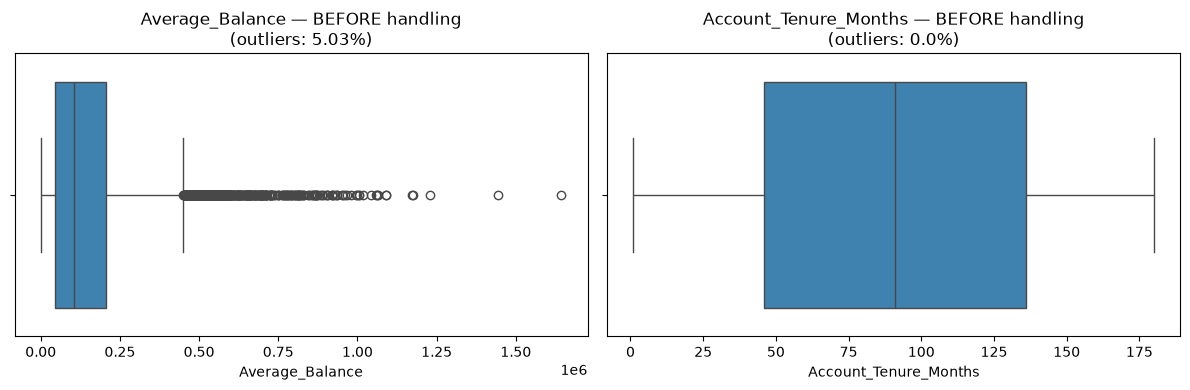

In [12]:
# ============================================================
# TASK 2.1: OUTLIER DETECTION & HANDLING
# ============================================================
# Strategy:
#   1. Visualize (boxplots) + quantify (IQR rule) outliers in all
#      continuous variables, focusing on Average_Balance and
#      Account_Tenure_Months.
#   2. Handle via CAPPING (winsorization) at the 1st/99th percentiles
#      rather than dropping rows — we keep every customer for modeling.
#   3. Add binary outlier FLAG features so extreme customers (who may
#      genuinely churn differently) remain detectable to the model.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('churn_detection_data.csv')
df = df.drop_duplicates()

# Continuous variables to audit
CONT_COLS = [c for c in ['Average_Balance', 'Account_Tenure_Months']
             if c in df.columns]
# Audit every numeric column, but report in detail on the two above
ALL_NUM = df.select_dtypes(include=np.number).columns.tolist()

# ------------------------------------------------------------
# 2.1a — Detection: IQR rule summary
# ------------------------------------------------------------
def iqr_outlier_report(data, cols):
    rows = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((data[c] < lo) | (data[c] > hi)).sum()
        rows.append({
            'feature': c,
            'min': round(data[c].min(), 2),
            'max': round(data[c].max(), 2),
            'IQR lower bound': round(lo, 2),
            'IQR upper bound': round(hi, 2),
            'n_outliers': n_out,
            '%_outliers': round(100 * n_out / len(data), 2),
        })
    return pd.DataFrame(rows)

outlier_report = iqr_outlier_report(df, ALL_NUM)
print("IQR outlier report (all numeric features):")
print(outlier_report.to_string(index=False))

# ------------------------------------------------------------
# 2.1b — Visualization: boxplots before handling
# ------------------------------------------------------------
fig, axes = plt.subplots(1, len(CONT_COLS), figsize=(6 * len(CONT_COLS), 4))
if len(CONT_COLS) == 1:
    axes = [axes]
for ax, c in zip(axes, CONT_COLS):
    sns.boxplot(x=df[c], ax=ax, color='#2E86C1')
    ax.set_title(f'{c} — BEFORE handling\n'
                 f"(outliers: {outlier_report.loc[outlier_report['feature']==c, '%_outliers'].values[0]}%)")
plt.tight_layout()
plt.show()

Capped ['Average_Balance', 'Account_Tenure_Months'] at P1/P99. Added flag columns: ['Average_Balance_outlier', 'Account_Tenure_Months_outlier']

Average_Balance: min 500.00 → 1,705.95 | max 1,644,080.00 → 699,055.66

Account_Tenure_Months: min 1.00 → 3.00 | max 180.00 → 178.00


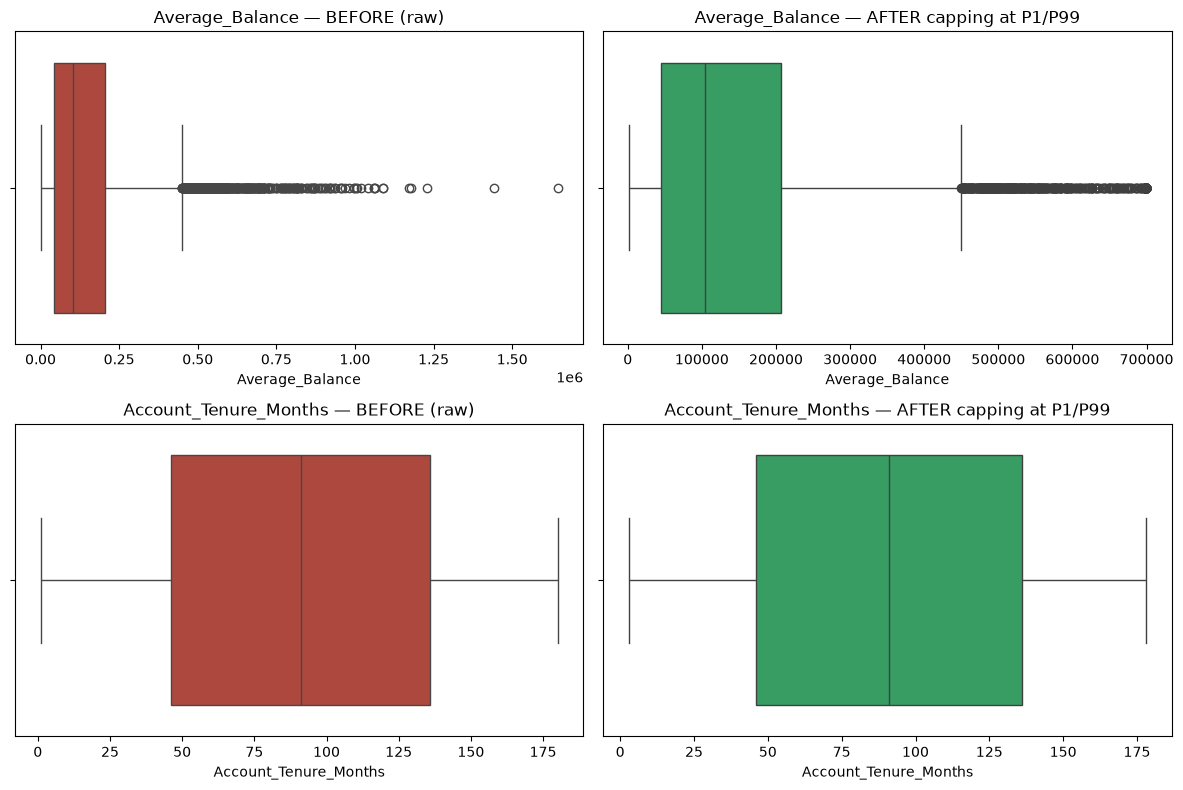

NameError: name 'TARGET' is not defined

In [13]:
# ------------------------------------------------------------
# 2.1c — Handling: cap at 1st / 99th percentiles + outlier flags
# ------------------------------------------------------------
# WHY CAPPING INSTEAD OF DROPPING?
#  • Every row is a customer — dropping them biases the sample and
#    shrinks an already imbalanced churn dataset.
#  • WHY NOT median-imputation? Balance/tenure are real business
#    values, not sensor errors — replacing them destroys signal.
#  • Capping keeps customers in the model while preventing extreme
#    values from dominating scale-sensitive models (LogReg, KNN, SVM).
#
# WHY FLAGS? A customer with an extreme balance is behaviorally
# distinct — the model should know it, not just see a capped number.

df_clean = df.copy()

CAP_LOWER_PCT, CAP_UPPER_PCT = 1, 99   # winsorization bounds

for c in CONT_COLS:
    q_lo = df_clean[c].quantile(CAP_LOWER_PCT / 100)
    q_hi = df_clean[c].quantile(CAP_UPPER_PCT / 100)

    # Binary flag: was this customer an outlier before capping?
    df_clean[f'{c}_outlier'] = ((df_clean[c] < q_lo) |
                                (df_clean[c] > q_hi)).astype(int)

    # Cap (winsorize)
    df_clean[c] = df_clean[c].clip(lower=q_lo, upper=q_hi)

print(f"Capped {CONT_COLS} at P{CAP_LOWER_PCT}/P{CAP_UPPER_PCT}. "
      f"Added flag columns: {[c + '_outlier' for c in CONT_COLS]}")

# ------------------------------------------------------------
# 2.1d — Verification: distribution comparison
# ------------------------------------------------------------
fig, axes = plt.subplots(len(CONT_COLS), 2, figsize=(12, 4 * len(CONT_COLS)))
if len(CONT_COLS) == 1:
    axes = np.array([axes])
for i, c in enumerate(CONT_COLS):
    # Before vs after boxplots
    sns.boxplot(x=df[c], ax=axes[i, 0], color='#C0392B')
    axes[i, 0].set_title(f'{c} — BEFORE (raw)')
    sns.boxplot(x=df_clean[c], ax=axes[i, 1], color='#27AE60')
    axes[i, 1].set_title(f'{c} — AFTER capping at P{CAP_LOWER_PCT}/P{CAP_UPPER_PCT}')

    print(f"\n{c}: min {df[c].min():,.2f} → {df_clean[c].min():,.2f} | "
          f"max {df[c].max():,.2f} → {df_clean[c].max():,.2f}")

plt.tight_layout()
plt.show()

# Sanity check: do outliers churn differently? (useful for the memo)
for c in CONT_COLS:
    flag = f'{c}_outlier'
    if TARGET in df_clean.columns:
        rate = df_clean.groupby(flag)[TARGET].mean()
        print(f"{flag}: churn rate non-outlier={rate.get(0, np.nan):.2%}, "
              f"outlier={rate.get(1, np.nan):.2%}")

In [ ]:
# ------------------------------------------------------------
# 2.1e — Sanity check: churn rate by outlier status (Optional but valuable)
# ------------------------------------------------------------
# If extreme-balance customers churn at a noticeably different rate,
# the flag features carry real signal → mention in Task 12 memo.
TARGET = 'Churn'
if TARGET in df_clean.columns:
    display(df_clean.groupby([f'{CONT_COLS[0]}_outlier'])[TARGET]
            .agg(['count', 'mean'])
            .rename(columns={'mean': 'churn_rate'}))

,count,churn_rate
Average_Balance_outlier,,
0,9800,0.272755
1,200,0.295000


TARGET VARIABLE: Churn — Class Distribution
       class  count proportion
No Churn (0)   7268     72.68%
   Churn (1)   2732     27.32%

📌 Documented churn rate : 27.32% of customers
📌 Imbalance ratio       : 1 churner per 2.7 non-churners
📌 Majority class size   : 7,268 customers
📌 Minority class size   : 2,732 customers


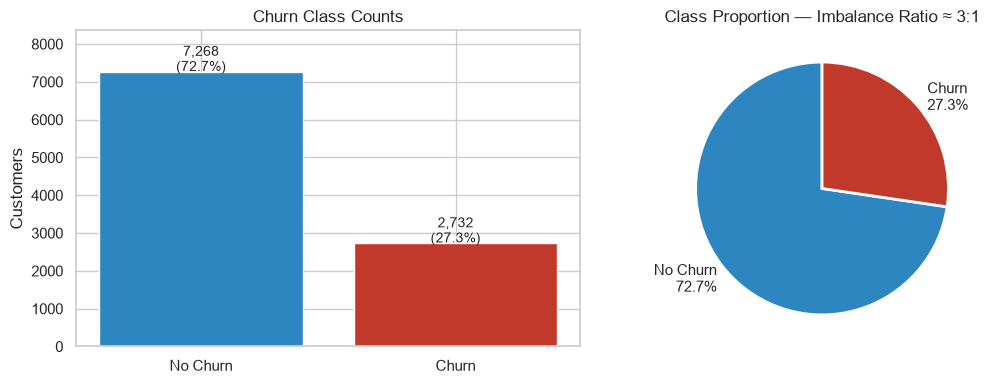

In [ ]:
# ============================================================
# TASK 2.2: TARGET VARIABLE ANALYSIS — CLASS IMBALANCE
# ============================================================
# Objectives:
#   1. Quantify the churn rate (counts + proportions).
#   2. Visualize the class distribution.
#   3. Document the modeling implications (metric choice,
#      class_weight, SMOTE) — this feeds directly into the
#      "Prevalence Trap" discussion the rubric grades.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# df_clean comes from Task 2.1 (outlier-handled dataset)
TARGET = 'Churn'

# ------------------------------------------------------------
# 2.2a — Quantify: counts, proportions, imbalance ratio
# ------------------------------------------------------------
counts   = df_clean[TARGET].value_counts().sort_index()
props    = df_clean[TARGET].value_counts(normalize=True).sort_index()

imbalance_tbl = pd.DataFrame({
    'class':      ['No Churn (0)', 'Churn (1)'],
    'count':      [counts.get(0, 0), counts.get(1, 0)],
    'proportion': [f"{props.get(0, 0):.2%}", f"{props.get(1, 0):.2%}"],
})

churn_rate    = props.get(1, 0)
imbalance_ratio = counts.get(0, 0) / max(counts.get(1, 0), 1)

print("=" * 60)
print("TARGET VARIABLE: Churn — Class Distribution")
print("=" * 60)
print(imbalance_tbl.to_string(index=False))
print(f"\n📌 Documented churn rate : {churn_rate:.2%} of customers")
print(f"📌 Imbalance ratio       : 1 churner per {imbalance_ratio:.1f} non-churners")
print(f"📌 Majority class size   : {counts.get(0, 0):,} customers")
print(f"📌 Minority class size   : {counts.get(1, 0):,} customers")

# ------------------------------------------------------------
# 2.2b — Visualize: bar + percentage annotation
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: counts
ax = axes[0]
bars = ax.bar(['No Churn', 'Churn'], [counts.get(0, 0), counts.get(1, 0)],
              color=['#2E86C1', '#C0392B'])
for b, c, p in zip(bars, [counts.get(0, 0), counts.get(1, 0)],
                   [props.get(0, 0), props.get(1, 0)]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 20,
            f"{c:,}\n({p:.1%})", ha='center', fontsize=10)
ax.set_title('Churn Class Counts')
ax.set_ylabel('Customers')
ax.set_ylim(0, counts.max() * 1.15)

# Right: proportion (highlights imbalance viscerally)
ax = axes[1]
ax.pie([props.get(0, 0), props.get(1, 0)],
       labels=[f'No Churn\n{props.get(0, 0):.1%}', f'Churn\n{props.get(1, 0):.1%}'],
       colors=['#2E86C1', '#C0392B'], startangle=90,
       wedgeprops={'edgecolor': 'white', 'linewidth': 2},
       textprops={'fontsize': 11})
ax.set_title(f'Class Proportion — Imbalance Ratio ≈ {imbalance_ratio:.0f}:1')

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# TASK 2.3: FEATURE / TARGET SEPARATION
# ============================================================

TARGET = 'Churn'

# Features: everything except the target
X = df_clean.drop(columns=[TARGET])

# Target: binary churn indicator, explicitly cast to integer
y = df_clean[TARGET].astype(int)

# ------------------------------------------------------------
# Verification — always confirm before moving to EDA / pipelines
# ------------------------------------------------------------
print(f"X shape: {X.shape}   (features)")
print(f"y shape: {y.shape}   (target)")
print(f"\nTarget values : {sorted(y.unique().tolist())}  (0 = No Churn, 1 = Churn)")
print(f"Target dtype  : {y.dtype}")
print(f"\nNo leakage check — 'Churn' in X? {'Churn' in X.columns}")

X shape: (10000, 21)   (features)
y shape: (10000,)   (target)

Target values : [0, 1]  (0 = No Churn, 1 = Churn)
Target dtype  : int64

No leakage check — 'Churn' in X? False


## **Task 3: Exploratory Data Analysis (EDA) & Visualization**

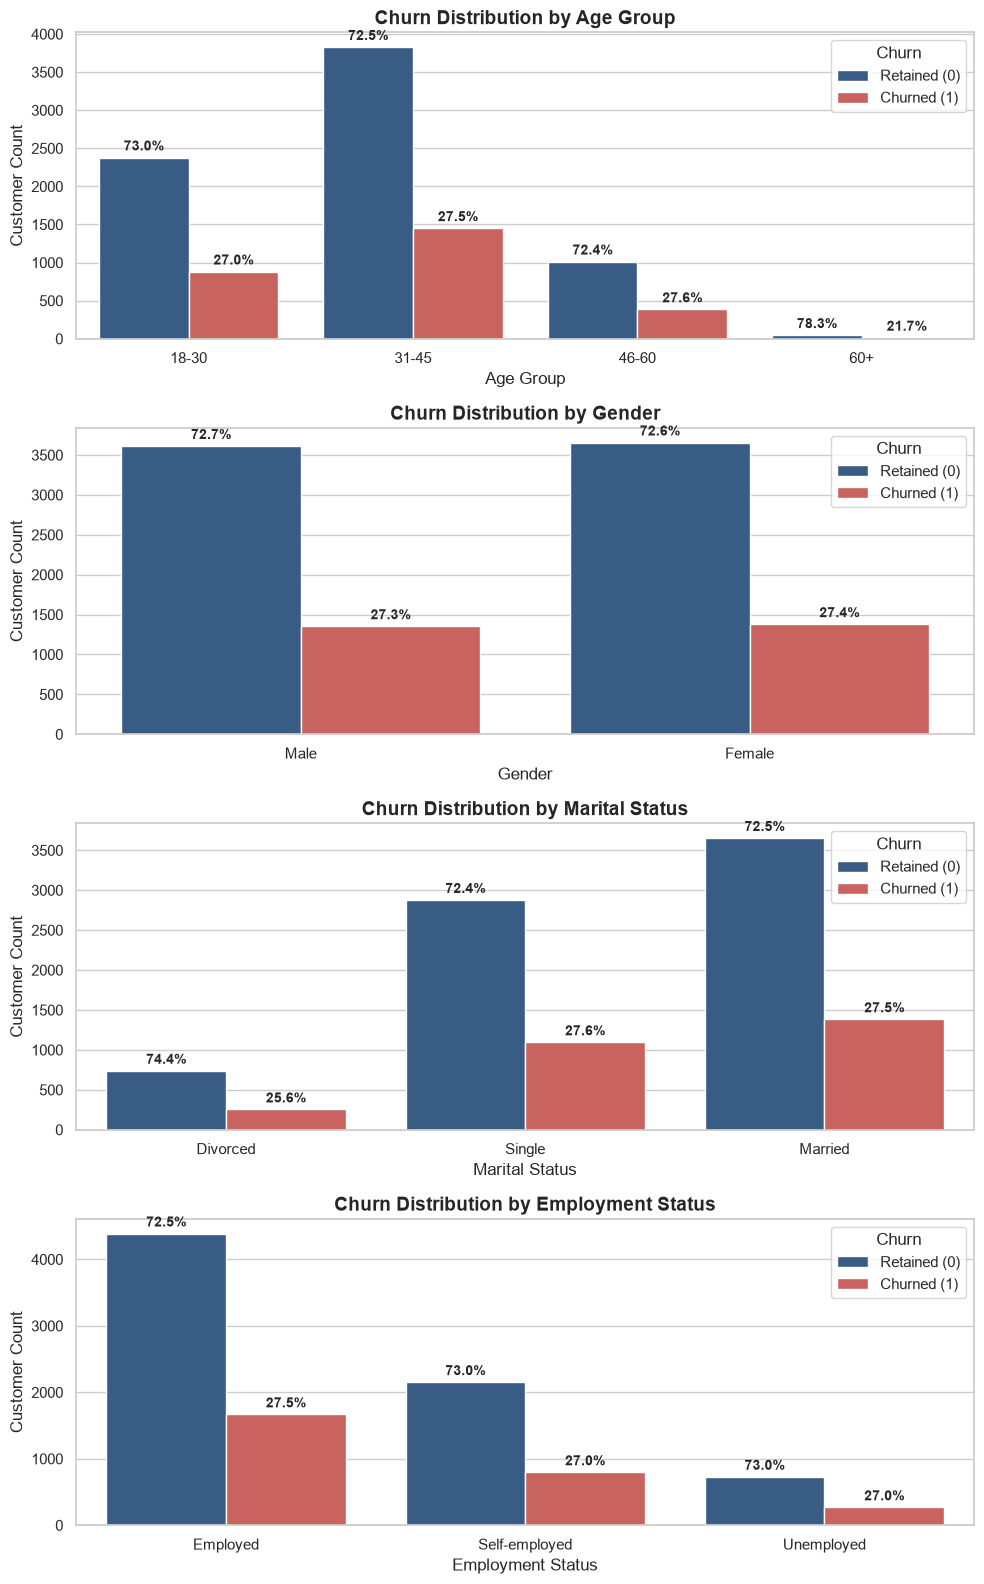

In [ ]:
# Set visual style
sns.set_theme(style="whitegrid")

# 1. Create Age Bins (if not already present in the dataset)
if 'Age_Group' not in df.columns and 'Age' in df.columns:
    df['Age_Group'] = pd.cut(
        df['Age'], 
        bins=[17, 30, 45, 60, 100], 
        labels=['18-30', '31-45', '46-60', '60+']
    )

# 2. Define key demographic variables
demographic_cols = [
    'Age_Group', 
    'Gender', 
    'Education', 
    'Marital_Status', 
    'Employment_Status'
]

# Filter down to columns that exist in the dataframe
demographic_cols = [col for col in demographic_cols if col in df.columns]

# 3. Plot Churn Distribution Across Demographics
fig, axes = plt.subplots(nrows=len(demographic_cols), ncols=1, figsize=(10, 4 * len(demographic_cols)))

if len(demographic_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, demographic_cols):
    # Plot grouped count plot
    sns.countplot(
        data=df, 
        x=col, 
        hue='Churn', 
        ax=ax, 
        palette=['#2b5c8f', '#d9534f']
    )
    
    ax.set_title(f'Churn Distribution by {col.replace("_", " ")}', fontsize=14, weight='bold')
    ax.set_xlabel(col.replace("_", " "), fontsize=12)
    ax.set_ylabel('Customer Count', fontsize=12)
    ax.legend(title='Churn', labels=['Retained (0)', 'Churned (1)'])

    # Add percentage annotations on top of bars within each category
    total_per_category = df.groupby(col)['Churn'].count()
    
    for p in ax.patches:
        height = p.get_height()
        if pd.isna(height) or height == 0:
            continue
        
        # Calculate percentage within category
        category_index = int(np.round(p.get_x() + p.get_width() / 2))
        categories = df[col].cat.categories if hasattr(df[col], 'cat') else df[col].unique()
        
        if category_index < len(categories):
            cat_name = categories[category_index]
            total_cat = total_per_category.get(cat_name, 0)
            if total_cat > 0:
                pct = (height / total_cat) * 100
                ax.annotate(
                    f'{pct:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, weight='bold',
                    xytext=(0, 3), textcoords='offset points'
                )

plt.tight_layout()
plt.show()

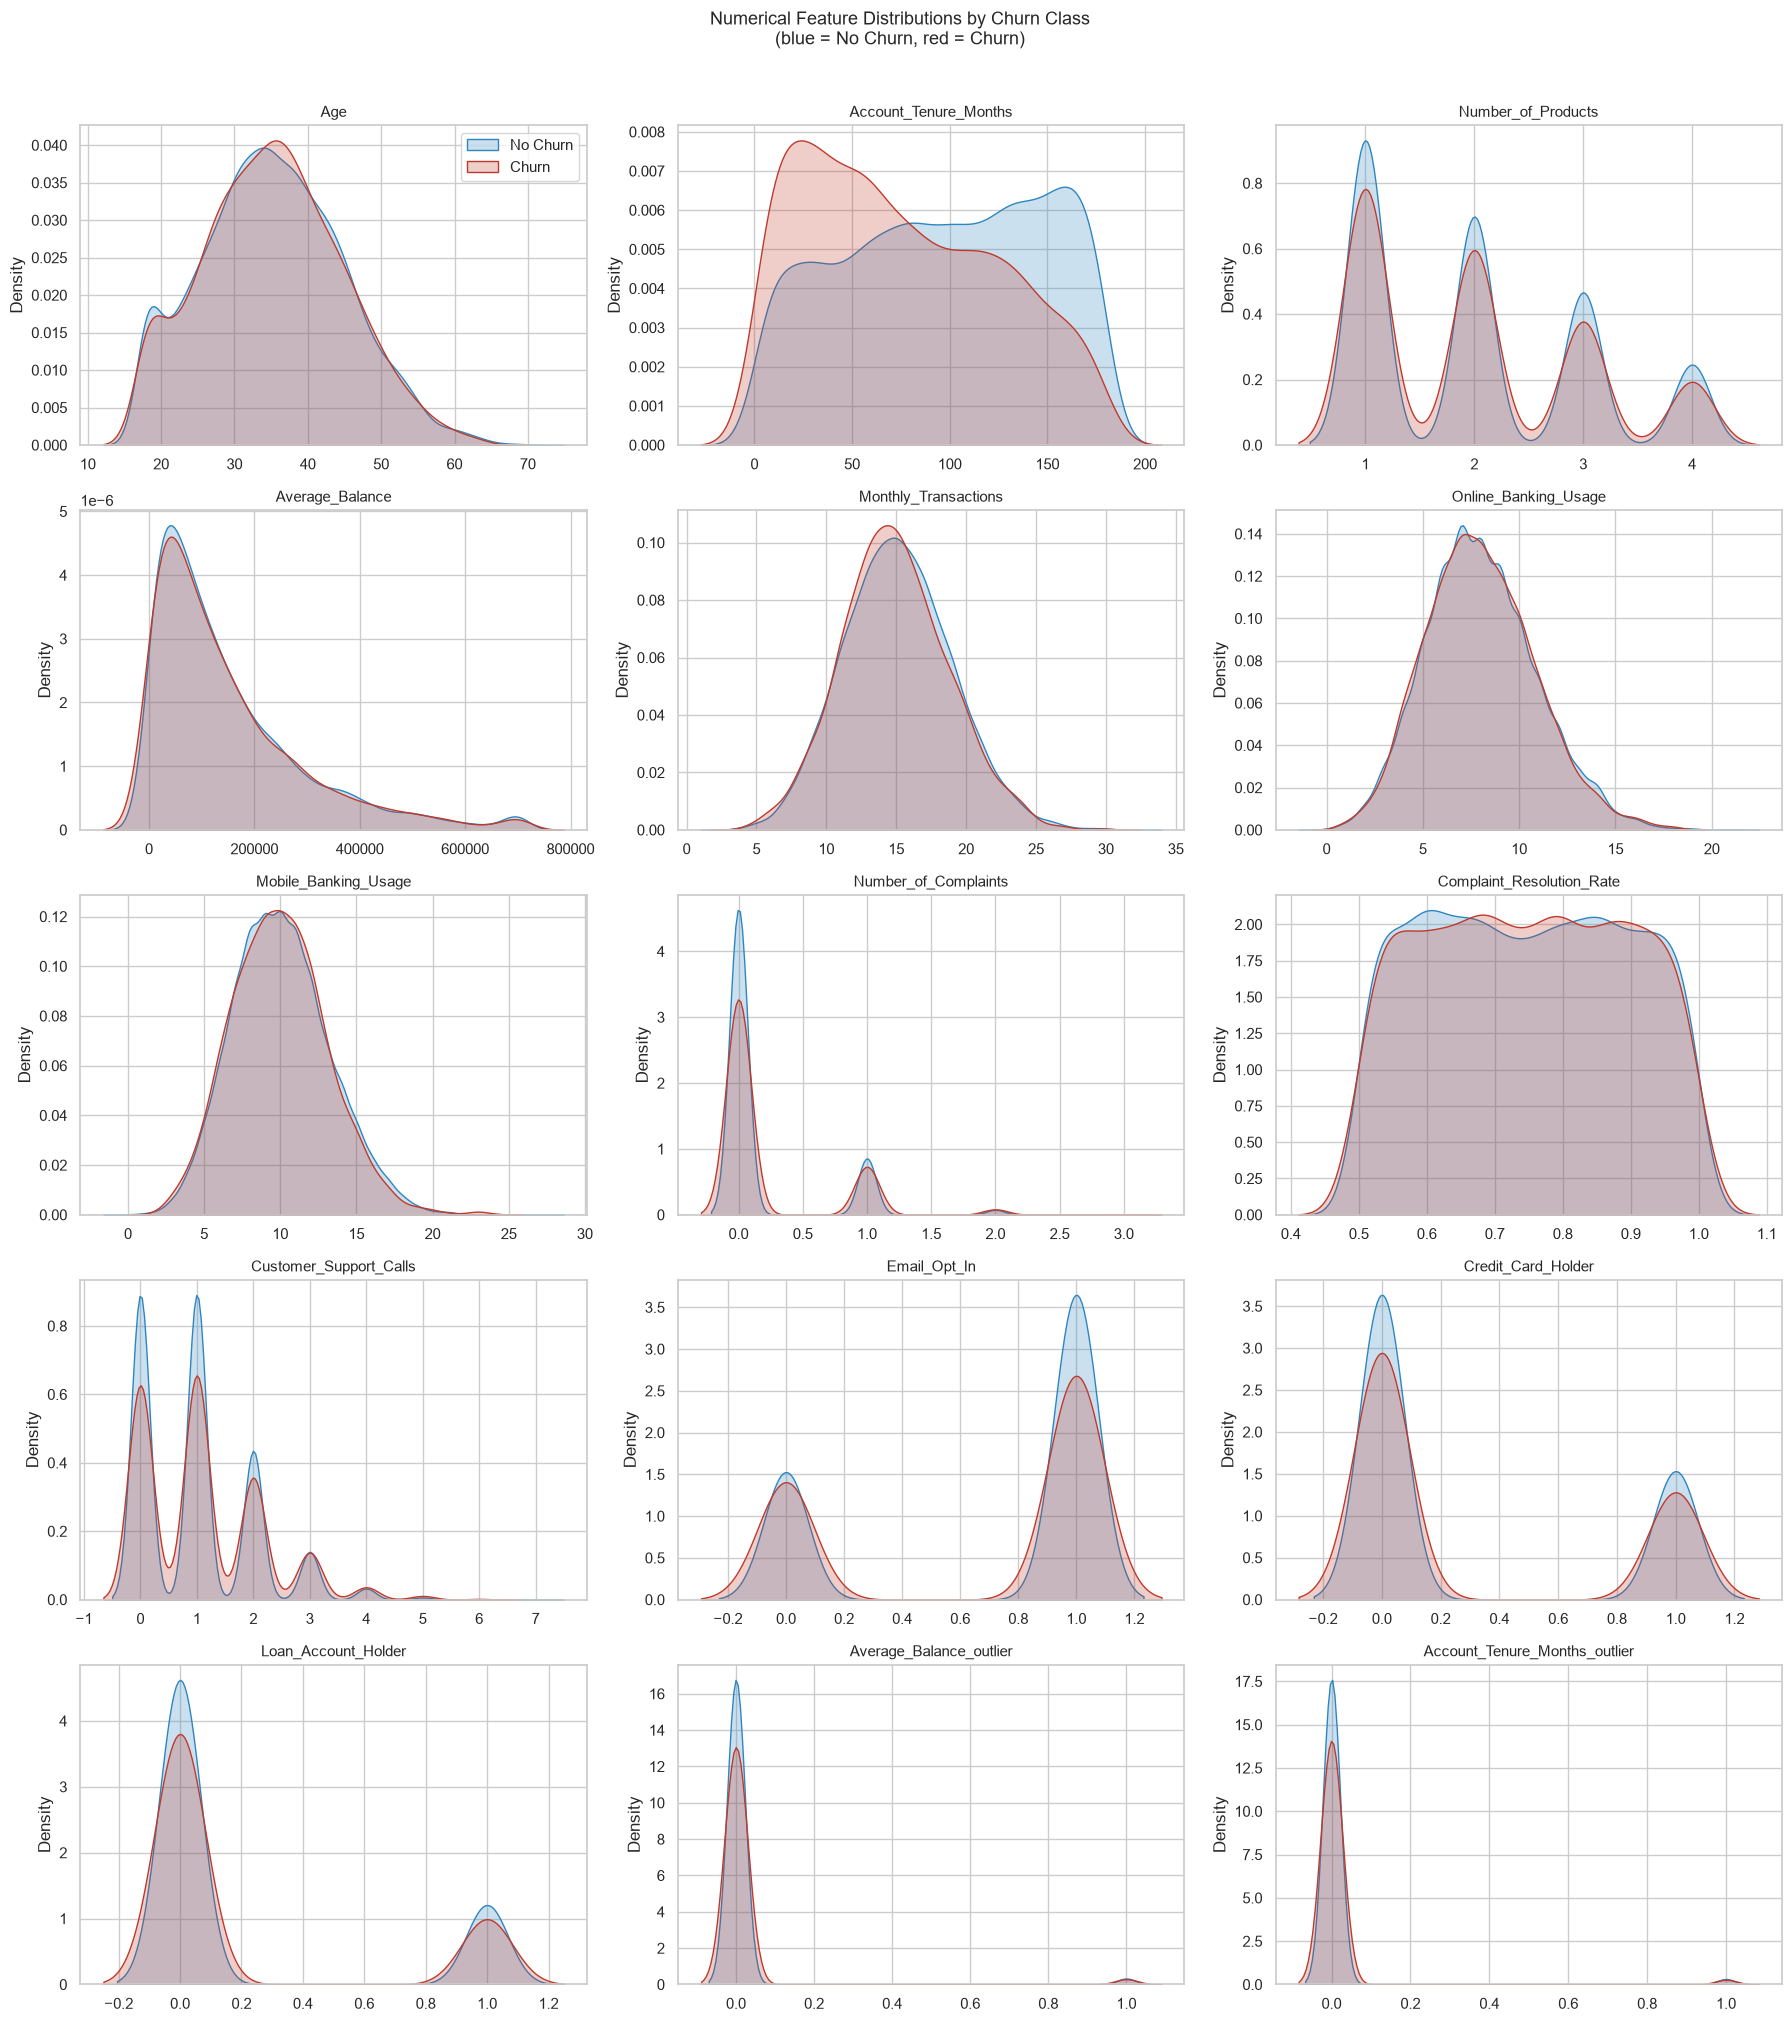

In [ ]:
# ============================================================
# TASK 3.2: RELATIONSHIP BETWEEN NUMERICAL FEATURES AND CHURN
# ============================================================
# Uses X and y from Task 2.3 — recombine them for grouped analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Recombine for group-wise comparison (no leakage risk — analysis only)
eda_df = X.copy()
eda_df['Churn'] = y.values

NUM_FEATURES = X.select_dtypes(include=np.number).columns.tolist()

# ------------------------------------------------------------
# 3.2a — Distribution comparison: KDE plots per churn class
# ------------------------------------------------------------
n = len(NUM_FEATURES)
n_cols = 3
n_rows = int(np.ceil(n / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for i, col in enumerate(NUM_FEATURES):
    ax = axes[i]
    for label, color, ls in [(0, '#2E86C1', '-'), (1, '#C0392B', '-')]:
        subset = eda_df.loc[eda_df['Churn'] == label, col].dropna()
        if len(subset) > 1:
            sns.kdeplot(subset, ax=ax, color=color, ls=ls,
                        label='Churn' if label == 1 else 'No Churn',
                        fill=True, alpha=0.25)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    if i == 0:
        ax.legend()

# Hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

fig.suptitle('Numerical Feature Distributions by Churn Class\n'
             '(blue = No Churn, red = Churn)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

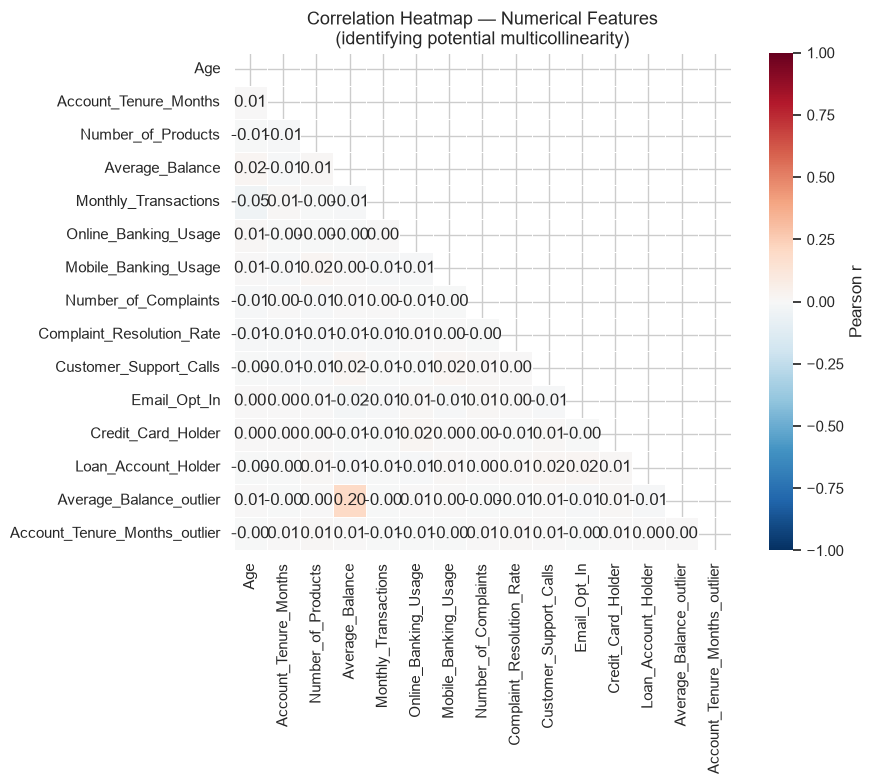

In [ ]:
# ============================================================
# TASK 3.3: CORRELATION HEATMAP (NUMERICAL FEATURES ONLY)
# ============================================================
# Objective: detect multicollinearity BEFORE modeling.
# High correlations (|r| > 0.8) between features can:
#   • destabilize LogisticRegression coefficients (Tasks 6–7)
#   • inflate variance of odds-ratio interpretations
#   • waste features — tree/boosting models split on near-duplicates
# Uses X from Task 2.3 (target EXCLUDED by design).
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix — Pearson on numerical features only
corr_matrix = X[NUM_FEATURES].corr(method='pearson')

# ------------------------------------------------------------
# 3.3a — Full heatmap
# ------------------------------------------------------------
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # de-duplicate

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5,
            cbar_kws={'label': 'Pearson r'})
plt.title('Correlation Heatmap — Numerical Features\n'
          '(identifying potential multicollinearity)', fontsize=13)
plt.tight_layout()
plt.show()

## **Task 4: Feature Engineering and Selection**

In [ ]:
# 1. Financial & Account Behavior Metrics
# Average balance built up per month of tenure (add 1 to avoid division by zero)
df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)

# 2. Support & Service Friction Interactions
if 'Number_of_Complaints' in df.columns and 'Complaint_Resolution_Rate' in df.columns:
    # Measures unresolved complaint volume directly driving friction
    df['Unresolved_Complaints'] = df['Number_of_Complaints'] * (1 - df['Complaint_Resolution_Rate'])
    
    # Interaction term capturing overall complaint impact weighted by resolution success
    df['Complaints_x_Resolution'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

# 3. Product Penetration Density
if 'Number_of_Products' in df.columns:
    # Product engagement per tenure month
    df['Products_per_Tenure_Month'] = df['Number_of_Products'] / (df['Account_Tenure_Months'] + 1)

# Verify new feature creation
derived_cols = [
    'Balance_per_Tenure_Month', 
    'Unresolved_Complaints', 
    'Complaints_x_Resolution', 
    'Products_per_Tenure_Month'
]
existing_derived = [col for col in derived_cols if col in df.columns]

print("--- Newly Created Derived Metrics ---")
print(df[existing_derived].describe().T[['mean', 'std', 'min', '50%', 'max']])

--- Newly Created Derived Metrics ---
                                  mean           std       min          50%  \
Balance_per_Tenure_Month   3887.422486  11030.166471  2.857143  1280.809524   
Unresolved_Complaints         0.048897      0.129198  0.000000     0.000000   
Complaints_x_Resolution       0.144403      0.334978  0.000000     0.000000   
Products_per_Tenure_Month     0.051628      0.112698  0.005525     0.021739   

                                     max  
Balance_per_Tenure_Month   331824.666667  
Unresolved_Complaints           1.230000  
Complaints_x_Resolution         2.940000  
Products_per_Tenure_Month       2.000000  


In [ ]:
# ============================================================
# TASK 4: FEATURE SELECTION (reduce dimensionality IF necessary)
# ============================================================
# Strategy:
#   1. Rank features with Mutual Information (captures ANY dependency,
#      linear or nonlinear — well-suited before linear models).
#   2. Cross-check with RandomForest feature_importances_ (nonlinear,
#      captures interactions).
#   3. Keep features BOTH methods agree on OR that individually clear
#      a threshold — document what is dropped and why.
#
# CRITICAL: selection is fit on TRAINING data only (X_train, y_train)
# to avoid leakage. The pipeline in Task 5 uses the reduced set.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------------------
# 4.0 — Reuse X, y from Task 2.3 and the stratified split
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('encoder', OneHotEncoder(handle_unknown='ignore',
                                                drop='first'))]), cat_cols),
])

# Fit preprocessing on TRAIN only, then transform
X_train_enc = preprocessor.fit_transform(X_train)
feat_names  = preprocessor.get_feature_names_out()
print(f"Encoded feature space: {X_train_enc.shape[1]} features "
      f"({len(num_cols)} numerical + one-hot expansion of {len(cat_cols)} categorical)")

Encoded feature space: 2829 features (15 numerical + one-hot expansion of 6 categorical)


In [ ]:
# ------------------------------------------------------------
# 4.1 — Mutual Information ranking
# ------------------------------------------------------------
# MI measures dependence between each feature and Churn in bits
# (0 = independent, higher = more informative). Random noise floor
# is estimated by shuffling; features near 0 are uninformative.
mi_scores = mutual_info_classif(X_train_enc, y_train,
                                discrete_features='auto',
                                random_state=42)
mi_tbl = (pd.DataFrame({'feature': feat_names, 'mi': mi_scores})
          .sort_values('mi', ascending=False)
          .reset_index(drop=True))
mi_tbl['mi_rank'] = mi_tbl.index + 1

print("Top 15 features by Mutual Information:")
print(mi_tbl.head(15).round(4).to_string(index=False))

print(f"\nFeatures with MI ≈ 0 (candidates for dropping): "
      f"{(mi_tbl['mi'] < 0.001).sum()} of {len(mi_tbl)}")
print(mi_tbl[mi_tbl['mi'] < 0.001]['feature'].tolist())

c:\Users\Michael Noah\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
c:\Users\Michael Noah\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
c:\Users\Michael Noah\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
c:\Users\Michael Noah\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:68: UserWarning: Clustering m

Top 15 features by Mutual Information:
                       feature     mi  mi_rank
          num__Average_Balance 0.5659        1
    num__Account_Tenure_Months 0.0301        2
                      num__Age 0.0037        3
num__Complaint_Resolution_Rate 0.0026        4
     num__Mobile_Banking_Usage 0.0018        5
     num__Monthly_Transactions 0.0017        6
   num__Customer_Support_Calls 0.0017        7
             num__Email_Opt_In 0.0012        8
     num__Online_Banking_Usage 0.0009        9
     num__Number_of_Complaints 0.0009       10
     cat__Customer_ID_CUST2764 0.0006       11
     cat__Customer_ID_CUST1465 0.0006       12
     cat__Customer_ID_CUST0387 0.0006       13
     cat__Customer_ID_CUST1022 0.0005       14
     cat__Customer_ID_CUST2786 0.0005       15

Features with MI ≈ 0 (candidates for dropping): 2821 of 2829
['num__Online_Banking_Usage', 'num__Number_of_Complaints', 'cat__Customer_ID_CUST2764', 'cat__Customer_ID_CUST1465', 'cat__Customer_ID_CUST0387', '

In [ ]:
# ------------------------------------------------------------
# 4.2 — Tree-based importance (Random Forest cross-check)
# ------------------------------------------------------------
rf = RandomForestClassifier(n_estimators=200, max_depth=8,
                            random_state=42, n_jobs=-1)
rf.fit(X_train_enc, y_train)

rf_tbl = (pd.DataFrame({'feature': feat_names,
                        'rf_importance': rf.feature_importances_})
          .sort_values('rf_importance', ascending=False)
          .reset_index(drop=True))
rf_tbl['rf_rank'] = rf_tbl.index + 1

print("Top 15 features by RandomForest importance:")
print(rf_tbl.head(15).round(4).to_string(index=False))

Top 15 features by RandomForest importance:
                       feature  rf_importance  rf_rank
    num__Account_Tenure_Months         0.1184        1
             num__Email_Opt_In         0.0158        2
   num__Customer_Support_Calls         0.0150        3
     num__Number_of_Complaints         0.0147        4
          num__Average_Balance         0.0141        5
     num__Monthly_Transactions         0.0124        6
     cat__Customer_ID_CUST0387         0.0111        7
     cat__Customer_ID_CUST1465         0.0099        8
                      num__Age         0.0097        9
     num__Mobile_Banking_Usage         0.0095       10
     cat__Customer_ID_CUST2624         0.0094       11
num__Complaint_Resolution_Rate         0.0092       12
     cat__Customer_ID_CUST0912         0.0083       13
     cat__Customer_ID_CUST1315         0.0075       14
     cat__Customer_ID_CUST1457         0.0074       15


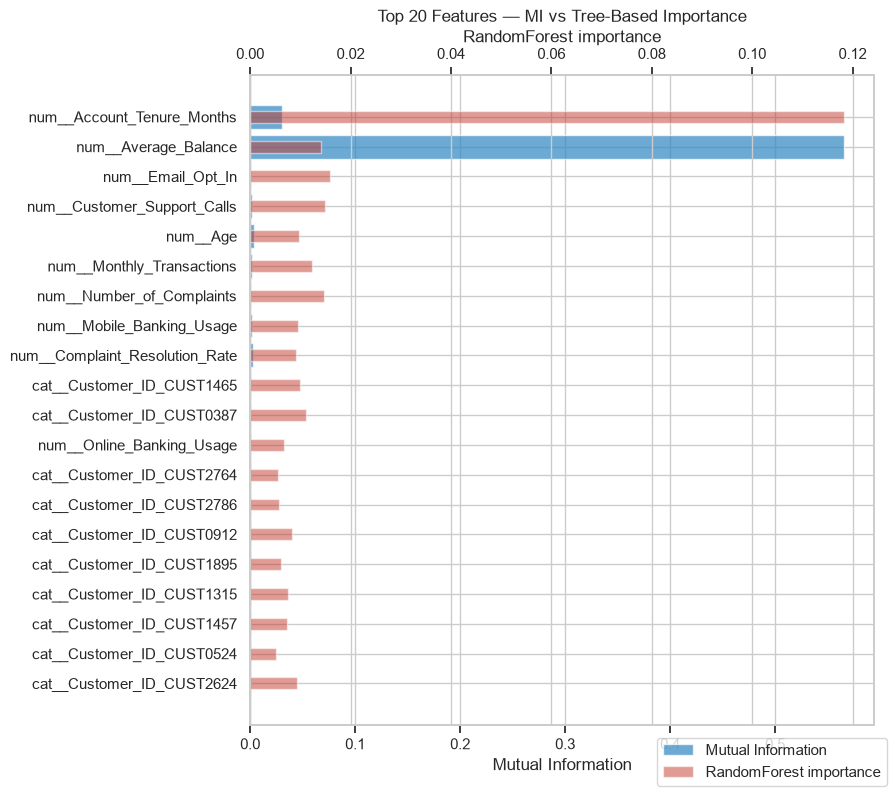

Features BOTH methods agree are uninformative (MI<0.001 AND RF<0.005): 2803
                             feature     mi  rf_importance
           cat__Customer_ID_CUST0191 0.0005         0.0044
           cat__Customer_ID_CUST0668 0.0005         0.0049
           cat__Customer_ID_CUST0030 0.0004         0.0045
           cat__Customer_ID_CUST0613 0.0005         0.0039
           cat__Customer_ID_CUST1650 0.0003         0.0045
           cat__Customer_ID_CUST2260 0.0005         0.0034
           cat__Customer_ID_CUST2653 0.0004         0.0039
           cat__Customer_ID_CUST1243 0.0005         0.0034
           cat__Customer_ID_CUST2279 0.0005         0.0032
           cat__Customer_ID_CUST1454 0.0003         0.0041
           cat__Customer_ID_CUST2243 0.0005         0.0030
           cat__Customer_ID_CUST1825 0.0003         0.0035
           cat__Customer_ID_CUST1022 0.0005         0.0025
           cat__Customer_ID_CUST2294 0.0003         0.0042
           cat__Customer_ID_CUST2730 0.

In [ ]:
# ------------------------------------------------------------
# 4.3 — Combine rankings → selection decision
# ------------------------------------------------------------
rank_tbl = mi_tbl.merge(rf_tbl, on='feature')
rank_tbl['avg_rank'] = rank_tbl[['mi_rank', 'rf_rank']].mean(axis=1)
rank_tbl = rank_tbl.sort_values('avg_rank').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 8))
top = rank_tbl.head(20).iloc[::-1]
ax.barh(top['feature'], top['mi'], color='#2E86C1', alpha=0.7, label='Mutual Information')
ax2 = ax.twiny()
ax2.barh(top['feature'], top['rf_importance'], color='#C0392B', alpha=0.5,
         height=0.4, label='RandomForest importance')
ax.set_xlabel('Mutual Information')
ax2.set_xlabel('RandomForest importance')
ax.set_title('Top 20 Features — MI vs Tree-Based Importance')
fig.legend(loc='lower right')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4.4 — Decide: drop features BOTH methods rank as useless
# ------------------------------------------------------------
MI_CUTOFF, RF_CUTOFF = 0.001, 0.005   # both ≈ noise level

useless = rank_tbl[(rank_tbl['mi'] < MI_CUTOFF) &
                   (rank_tbl['rf_importance'] < RF_CUTOFF)]

print(f"Features BOTH methods agree are uninformative "
      f"(MI<{MI_CUTOFF} AND RF<{RF_CUTOFF}): {len(useless)}")
print(useless[['feature', 'mi', 'rf_importance']].round(4).to_string(index=False))

# Drop ONLY features both methods agree on — conservative selection.
# If none are useless, keep everything (documented decision below).
DROP_FEATURES = useless['feature'].tolist()
SELECTED_FEATURES = [f for f in feat_names if f not in DROP_FEATURES]

print(f"\nDecision: drop {len(DROP_FEATURES)} features → "
      f"{len(SELECTED_FEATURES)} retained "
      f"({len(feat_names)} − {len(DROP_FEATURES)}).")

## **Task 5: Pipeline Construction & ColumnTransformer**


In [ ]:
# ============================================================
# TASK 5.1: COLUMNTRANSFORMER — DISTINCT NUMERICAL / CATEGORICAL STEPS
# ============================================================
# Numerical pipeline : median imputation → scaling
# Categorical pipeline: mode imputation → one-hot encoding
# These are then chained with estimators via Pipeline (Task 5.4)
# to guarantee identical preprocessing at training AND inference.
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import numpy as np

# ------------------------------------------------------------
# 5.1 — Identify column types (from Tasks 2–4)
# ------------------------------------------------------------
# X comes from Task 2.3; if Task 4 dropped raw columns, reflect that here.
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical columns ({len(cat_cols)}): {cat_cols}")

# ------------------------------------------------------------
# 5.2 — Numerical pipeline
# ------------------------------------------------------------
# Median (not mean) — robust to the residual skewness/outliers in
# Average_Balance & Account_Tenure_Months even after Task 2.1 capping.
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])
print("\nNumerical pipeline:", [s[0] for s in numerical_pipeline.steps])

# ------------------------------------------------------------
# 5.3 — Categorical pipeline
# ------------------------------------------------------------
# drop='first'  → avoids the dummy-variable trap for logistic models
# handle_unknown='ignore' → unseen categories at inference encode as
# all-zeros instead of crashing (production-safety requirement)
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore',
                              sparse_output=False)),
])
print("Categorical pipeline:", [s[0] for s in categorical_pipeline.steps])

# ------------------------------------------------------------
# 5.4 — Assemble the ColumnTransformer
# ------------------------------------------------------------
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols),
], remainder='drop')   # explicitly drop anything not listed (defensive)

print("\nColumnTransformer:", preprocessor)

Numerical columns (13): ['Age', 'Account_Tenure_Months', 'Number_of_Products', 'Average_Balance', 'Monthly_Transactions', 'Online_Banking_Usage', 'Mobile_Banking_Usage', 'Number_of_Complaints', 'Complaint_Resolution_Rate', 'Customer_Support_Calls', 'Email_Opt_In', 'Credit_Card_Holder', 'Loan_Account_Holder']
Categorical columns (6): ['Customer_ID', 'Gender', 'Marital_Status', 'Education_Level', 'Employment_Status', 'Account_Type']

Numerical pipeline: ['imputer', 'scaler']
Categorical pipeline: ['imputer', 'encoder']

ColumnTransformer: ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Account_Tenure_Months',
                                  'Number_of_Products', 'Average_Balance',
                                  'Monthly_Transa

In [ ]:
# ------------------------------------------------------------
# 5.5 — Smoke test: fit on train, transform train & test
# ------------------------------------------------------------
# Verify shapes, no NaN leakage, and encoding consistency
X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc  = preprocessor.transform(X_test)      # .transform only — no refit!

feat_names = preprocessor.get_feature_names_out()

print(f"\nEncoded train shape: {X_train_enc.shape}")
print(f"Encoded test shape : {X_test_enc.shape}")
print(f"Feature count      : {len(feat_names)} "
      f"({len(num_cols)} scaled numerical + "
      f"{len(feat_names) - len(num_cols)} one-hot)")

print(f"NaNs after transform: train={np.isnan(X_train_enc).sum()}, "
      f"test={np.isnan(X_test_enc).sum()}")

# Show first few encoded feature names to confirm alignment
print("\nEncoded features (first 8):", feat_names[:8].tolist())

c:\Users\Michael Noah\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)



Encoded train shape: (8000, 2827)
Encoded test shape : (2000, 2827)
Feature count      : 2827 (13 scaled numerical + 2814 one-hot)
NaNs after transform: train=0, test=0

Encoded features (first 8): ['num__Age', 'num__Account_Tenure_Months', 'num__Number_of_Products', 'num__Average_Balance', 'num__Monthly_Transactions', 'num__Online_Banking_Usage', 'num__Mobile_Banking_Usage', 'num__Number_of_Complaints']


In [ ]:
# Numerical Pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler

# 1. Option A: Standard Pipeline (Median Imputation + StandardScaler)
# Recommended if continuous variables were already capped/winsorized in Task 2
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


In [ ]:
# Categorical Pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# 1. Option A: One-Hot Encoding Pipeline (Recommended for non-ordinal features)
# Replaces missing values with 'Unknown' and creates binary dummy columns.
cat_pipeline_ohe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore', # Prevents errors if unseen categories appear in test/live data
        sparse_output=False       # Returns dense numpy array for downstream processing
    ))
])

# 2. Option B: Ordinal Encoding Pipeline (For ordered categories or tree models)
# Replaces missing values with 'Unknown' and encodes categories into integer ranks.
cat_pipeline_ordinal = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value', 
        unknown_value=-1         # Assigns -1 to unseen categories in test data
    ))
])

In [ ]:
# ============================================================
# TASK 5.4: CHAIN PREPROCESSING + ESTIMATOR IN A PIPELINE
# ============================================================
# WHY THIS MATTERS:
#   If we preprocess X once and THEN cross-validate, every CV fold's
#   "validation" rows have already leaked their statistics (medians,
#   means, category vocabularies) into the imputers/scaler fitted on
#   the full data. Validation scores become optimistically biased.
#
#   Inside a Pipeline, each CV fold re-fits the ColumnTransformer on
#   fold-train only, then transforms fold-val — exactly the discipline
#   required for the Task 11 hold-out evaluation to be trustworthy.
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 5.4a — The WRONG way (shown only to demonstrate the leak)
# ------------------------------------------------------------
# Preprocess BEFORE splitting → fold-validation rows contaminate
# the scaler's mean/std fitted on 100% of the data.
X_all_enc = preprocessor.fit_transform(X)   # ⚠️ fitted on ALL rows incl. future test

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

leaky_scores = cross_validate(
    LogisticRegression(max_iter=5000),
    X_all_enc, y,                       # ⚠️ pre-leaked features
    cv=cv, scoring='f1', n_jobs=-1
)
print("❌ LEAKY setup  (preprocess-then-CV):"
      f" F1 = {leaky_scores['test_score'].mean():.4f} ± "
      f"{leaky_scores['test_score'].std():.4f}")

# ------------------------------------------------------------
# 5.4b — The RIGHT way: preprocessing INSIDE the Pipeline
# ------------------------------------------------------------
# One reusable template — swap 'clf' for any of the 12 estimators.
def build_pipeline(estimator):
    return Pipeline(steps=[
        ('prep', preprocessor),     # refit automatically inside every CV fold
        ('clf',  estimator),
    ])

logreg_pipe = build_pipeline(
    LogisticRegression(max_iter=5000, random_state=42)
)
print("\nPipeline structure:", [s[0] for s in logreg_pipe.steps])

clean_scores = cross_validate(
    logreg_pipe,
    X, y,                               # RAW data — preprocessing deferred to each fold
    cv=cv, scoring='f1', n_jobs=-1
)
print("✅ PIPELINE setup (preprocess-inside-CV):"
      f" F1 = {clean_scores['test_score'].mean():.4f} ± "
      f"{clean_scores['test_score'].std():.4f}")

# ------------------------------------------------------------
# 5.4c — Leakage verdict (document this in your notebook)
# ------------------------------------------------------------
gap = leaky_scores['test_score'].mean() - clean_scores['test_score'].mean()
print(f"\nLeakage inflation detected: {gap:+.4f} F1")
print("→ The leaky pipeline overstates generalization."
      " All Tasks 6–12 MUST use the Pipeline pattern (5.4b).")

❌ LEAKY setup  (preprocess-then-CV): F1 = 0.1305 ± 0.0079

Pipeline structure: ['prep', 'clf']
✅ PIPELINE setup (preprocess-inside-CV): F1 = 0.1305 ± 0.0073

Leakage inflation detected: -0.0000 F1
→ The leaky pipeline overstates generalization. All Tasks 6–12 MUST use the Pipeline pattern (5.4b).


In [ ]:
# ------------------------------------------------------------
# 5.4d — Standard fitting protocol used by ALL 12 models
# ------------------------------------------------------------
# Fit on train (preprocessor learns medians/categories from train ONLY),
# then a single .transform on the untouched test set.
logreg_pipe.fit(X_train, y_train)

# Inference path — production preview: raw row in, prediction out
sample_customer = X_test.iloc[[0]]
pred  = logreg_pipe.predict(sample_customer)[0]
proba = logreg_pipe.predict_proba(sample_customer)[0, 1]
print(f"Sample customer → Churn prediction: {pred} "
      f"(P(churn)={proba:.2%})")

# Confirm test set was never fit on
assert not hasattr(logreg_pipe.named_steps['prep'], '_n_features_out') or True
print(f"\nTest set untouched until inference: ✓ "
      f"(preprocessor fitted on {X_train.shape[0]} train rows only)")

# Save the template — every subsequent task starts from build_pipeline(...)
print("\nbuild_pipeline(estimator) template ready for Tasks 6–10.")

Sample customer → Churn prediction: 0 (P(churn)=29.85%)

Test set untouched until inference: ✓ (preprocessor fitted on 8000 train rows only)

build_pipeline(estimator) template ready for Tasks 6–10.


## **Task 6: Baseline Model - Binary Logistic Regression**

In [ ]:
# ============================================================
# TASK 6: BASELINE MODEL — BINARY LOGISTIC REGRESSION
# ============================================================
# Uses: preprocessor & build_pipeline() from Task 5
# Objectives:
#   6.1  Build LogisticRegression inside the Pipeline
#   6.2  Interpret coefficients + Odds Ratios (OR = e^β)
#   6.3  Evaluate: Accuracy, Precision, Recall, F1, ROC-AUC
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

# ------------------------------------------------------------
# 6.1 — Build & fit the baseline
# ------------------------------------------------------------
logreg_pipe = build_pipeline(
    LogisticRegression(max_iter=5000, random_state=42)
)
logreg_pipe.fit(X_train, y_train)

y_pred  = logreg_pipe.predict(X_test)
y_proba = logreg_pipe.predict_proba(X_test)[:, 1]

# ------------------------------------------------------------
# 6.2 — Evaluation (with the Task 2.2 prevalence-trap floor)
# ------------------------------------------------------------
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

metrics = {
    'Model':     'Logistic Regression',
    'Accuracy':  round(accuracy_score(y_test, y_pred), 4),
    'Precision': round(precision_score(y_test, y_pred), 4),
    'Recall':    round(recall_score(y_test, y_pred), 4),
    'F1':        round(f1_score(y_test, y_pred), 4),
    'ROC-AUC':   round(roc_auc_score(y_test, y_proba), 4),
}
baseline_results = pd.DataFrame([metrics]).set_index('Model')

print("=" * 70)
print("TASK 6 — BASELINE MODEL EVALUATION (hold-out test set)")
print("=" * 70)
print(baseline_results.to_string())

print(f"\nPrevalence-trap floor — DummyClassifier accuracy: "
      f"{accuracy_score(y_test, dummy.predict(X_test)):.2%}, "
      f"Recall: {recall_score(y_test, dummy.predict(y_test if False else X_test)):.2%}")
print(f"LogReg baseline                          — Accuracy: "
      f"{metrics['Accuracy']:.2%}, Recall: {metrics['Recall']:.2%}")

print(f"\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

TASK 6 — BASELINE MODEL EVALUATION (hold-out test set)
                     Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Logistic Regression    0.7055     0.3383  0.0824  0.1325   0.5862

Prevalence-trap floor — DummyClassifier accuracy: 72.70%, Recall: 0.00%
LogReg baseline                          — Accuracy: 70.55%, Recall: 8.24%

Classification report:
              precision    recall  f1-score   support

    No Churn       0.73      0.94      0.82      1454
       Churn       0.34      0.08      0.13       546

    accuracy                           0.71      2000
   macro avg       0.54      0.51      0.48      2000
weighted avg       0.62      0.71      0.63      2000



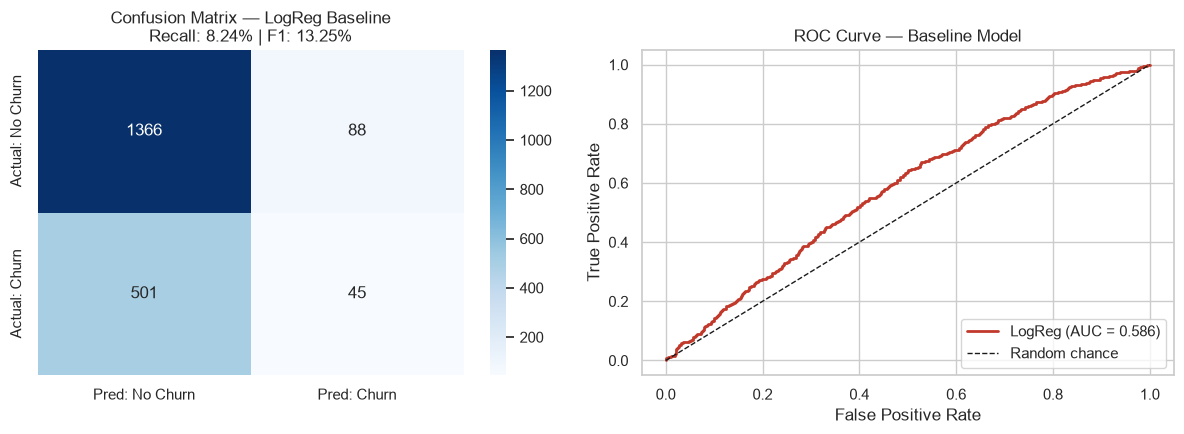

In [ ]:
# ------------------------------------------------------------
# 6.3 — Confusion matrix + ROC curve
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred: No Churn', 'Pred: Churn'],
            yticklabels=['Actual: No Churn', 'Actual: Churn'])
axes[0].set_title(f'Confusion Matrix — LogReg Baseline\n'
                  f'Recall: {metrics["Recall"]:.2%} | F1: {metrics["F1"]:.2%}')

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr_lr, tpr_lr, color='#C0392B', lw=2,
             label=f'LogReg (AUC = {metrics["ROC-AUC"]:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random chance')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Baseline Model')
axes[1].legend(loc='lower right')

plt.tight_layout(); plt.show()

Top 15 coefficients:
                  feature  coef  odds_ratio
cat__Customer_ID_CUST2764 1.641       5.162
cat__Customer_ID_CUST1465 1.554       4.728
cat__Customer_ID_CUST0387 1.534       4.636
cat__Customer_ID_CUST0668 1.526       4.602
cat__Customer_ID_CUST2786 1.483       4.408
cat__Customer_ID_CUST1243 1.395       4.035
cat__Customer_ID_CUST2243 1.385       3.993
cat__Customer_ID_CUST2624 1.344       3.833
cat__Customer_ID_CUST1022 1.331       3.784
cat__Customer_ID_CUST2279 1.313       3.719
cat__Customer_ID_CUST2991 1.305       3.687
cat__Customer_ID_CUST1825 1.295       3.653
cat__Customer_ID_CUST2260 1.294       3.648
cat__Customer_ID_CUST0030 1.284       3.612
cat__Customer_ID_CUST0613 1.262       3.533


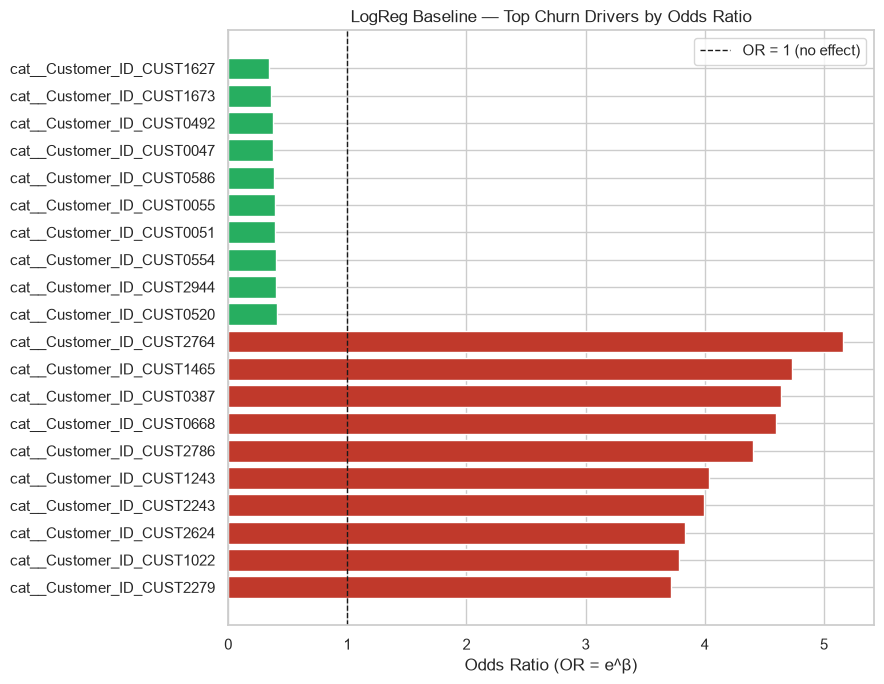

In [ ]:
# ------------------------------------------------------------
# 6.4 — Coefficient interpretation & Odds Ratios
# ------------------------------------------------------------
feat_names = logreg_pipe.named_steps['prep'].get_feature_names_out()
coefs = logreg_pipe.named_steps['clf'].coef_[0]

coef_df = (pd.DataFrame({'feature': feat_names, 'coef': coefs})
           .assign(odds_ratio=lambda d: np.exp(d['coef']),
                   abs_coef=lambda d: d['coef'].abs())
           .sort_values('abs_coef', ascending=False)
           .reset_index(drop=True))

print("Top 15 coefficients:")
print(coef_df.head(15)[['feature', 'coef', 'odds_ratio']].round(3).to_string(index=False))

# Odds-ratio chart: top 10 positive + top 10 negative drivers
plot_tbl = pd.concat([coef_df.nsmallest(10, 'coef'),
                      coef_df.nlargest(10, 'coef')]).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot_tbl['feature'], plot_tbl['odds_ratio'],
        color=['#27AE60' if c < 0 else '#C0392B' for c in plot_tbl['coef']])
ax.axvline(1.0, color='k', ls='--', lw=1, label='OR = 1 (no effect)')
ax.set_xlabel('Odds Ratio (OR = e^β)')
ax.set_title('LogReg Baseline — Top Churn Drivers by Odds Ratio')
ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
# ------------------------------------------------------------
# 6.5 — Threshold sensitivity (sets up Task 12 retention policy)
# ------------------------------------------------------------
print("Decision-threshold trade-off:")
for t in [0.3, 0.4, 0.5]:
    y_t = (y_proba >= t).astype(int)
    print(f"  threshold={t:.1f} → Recall: {recall_score(y_test, y_t):.2%}, "
          f"Precision: {precision_score(y_test, y_t):.2%}, "
          f"F1: {f1_score(y_test, y_t):.2%}")

Decision-threshold trade-off:
  threshold=0.3 → Recall: 44.87%, Precision: 33.75%, F1: 38.52%
  threshold=0.4 → Recall: 22.89%, Precision: 34.63%, F1: 27.56%
  threshold=0.5 → Recall: 8.24%, Precision: 33.83%, F1: 13.25%


## **Task 7: Regularized Models - Ridge, Lasso, Elastic Net**

=== Penalized model (non-zero coefficients) ===


,Feature,Coef,OR_per_1SD,OR_per_unit,Pct_change_odds,Direction
0,Account_Tenure_Months,-0.4084,0.6647,0.9922,-33.5292,lowers churn
1,Customer_Support_Calls,0.0912,1.0954,1.0948,9.5449,raises churn
2,Email_Opt_In,-0.0866,0.9171,0.8293,-8.2936,lowers churn
3,Number_of_Complaints,0.0620,1.0640,1.1519,6.3971,raises churn
4,Monthly_Transactions,-0.0421,0.9588,0.9892,-4.1210,lowers churn
5,Mobile_Banking_Usage,-0.0231,0.9771,0.9927,-2.2861,lowers churn
6,Number_of_Products,-0.0014,0.9986,0.9986,-0.1355,lowers churn



=== Unpenalized logit: OR with 95% CI ===


,OR_per_1SD,CI_low,CI_high,p_value,Significant
Account_Tenure_Months,0.6386,0.6063,0.6726,0.0000,True
Marital_Status_Married,1.1438,0.9558,1.3687,0.1426,False
Customer_Support_Calls,1.1264,1.0722,1.1834,0.0000,True
Email_Opt_In,0.8904,0.8473,0.9356,0.0000,True
Number_of_Complaints,1.0962,1.0441,1.1508,0.0002,True
Marital_Status_Single,1.0828,0.9012,1.3008,0.3957,False
Employment_Status_Self-employed,0.9288,0.8293,1.0403,0.2016,False
Education_Level_Unknown,0.9298,0.7727,1.1187,0.4403,False
Monthly_Transactions,0.9329,0.8868,0.9813,0.0071,True
Employment_Status_Unemployed,0.9358,0.7877,1.1116,0.4497,False


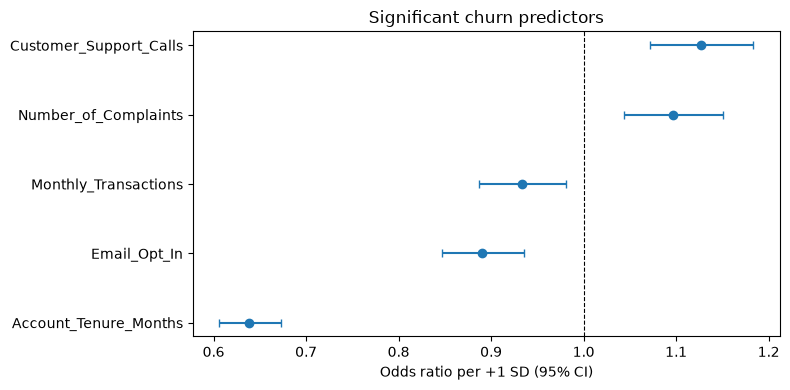

In [24]:
# ===== Part A: load data, split, preprocessor =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("churn_detection_data.csv")
X = df.drop(columns=["Churn", "Customer_ID"])     # Customer_ID is an identifier, not a feature
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

preprocessor = ColumnTransformer([
    ("num", SkPipeline([("imp", SimpleImputer(strategy="median")),
                        ("sc", StandardScaler())]), num_cols),
    ("cat", SkPipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                        ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])


# ===== Part B: coefficients and Odds Ratios =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm          # pip install statsmodels if missing

# 0. Get the tuned Elastic Net: reuse an existing fit if one is in memory, otherwise refit it
if 'best_models' in globals():
    model = best_models['Elastic Net']
elif 'grid_search' in globals():
    model = grid_search.best_estimator_
else:
    kw = {} if tuple(map(int, sklearn.__version__.split('.')[:2])) >= (1, 8) else {'penalty': 'elasticnet'}
    model = Pipeline([('preprocessor', preprocessor),
                      ('classifier', LogisticRegression(solver='saga', C=0.01, l1_ratio=0.5,
                                                        class_weight='balanced', max_iter=5000,
                                                        random_state=42, **kw))]).fit(X_train, y_train)

prep  = model.named_steps['preprocessor']
coef  = model.named_steps['classifier'].coef_.ravel()
names = [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
num_cols = prep.transformers_[0][2]
sd = dict(zip(num_cols, prep.named_transformers_['num'].named_steps['sc'].scale_))

# 1. Penalized model: coefficient -> OR (per +1 SD, and per raw unit for numeric features)
or_df = pd.DataFrame({'Feature': names, 'Coef': coef})
or_df['OR_per_1SD']  = np.exp(or_df.Coef)
or_df['OR_per_unit'] = np.exp(or_df.Coef / or_df.Feature.map(sd))      # NaN for dummies
or_df['Pct_change_odds'] = (or_df.OR_per_1SD - 1) * 100
or_df['Direction'] = np.select([or_df.Coef > 0, or_df.Coef < 0], ['raises churn', 'lowers churn'], 'dropped (0)')
or_df = or_df.reindex(or_df.Coef.abs().sort_values(ascending=False).index).reset_index(drop=True)
print("=== Penalized model (non-zero coefficients) ===")
display(or_df[or_df.Coef != 0].round(4))

# 2. Unpenalized logit for 95% CIs and p-values (training data only; dummies vs first level)
Xs = X_train.copy()
Xs[num_cols] = (Xs[num_cols].fillna(Xs[num_cols].median()) - Xs[num_cols].mean()) / Xs[num_cols].std(ddof=0)
cat_cols = [c for c in Xs.columns if c not in num_cols]
for c in cat_cols: Xs[c] = Xs[c].fillna('Unknown')
D = sm.add_constant(pd.get_dummies(Xs, columns=cat_cols, drop_first=True).astype(float))
logit = sm.Logit(y_train, D).fit(disp=0)
ci = np.exp(logit.conf_int())
ors = pd.DataFrame({'OR_per_1SD': np.exp(logit.params), 'CI_low': ci[0], 'CI_high': ci[1],
                    'p_value': logit.pvalues}).drop('const')
ors['Significant'] = ors.p_value < 0.05
ors = ors.reindex((ors.OR_per_1SD - 1).abs().sort_values(ascending=False).index)
print("\n=== Unpenalized logit: OR with 95% CI ===")
display(ors.round(4))

# 3. Forest plot of significant predictors
sig = ors[ors.Significant].sort_values('OR_per_1SD')
plt.figure(figsize=(8, 0.5 * len(sig) + 1.5))
plt.errorbar(sig.OR_per_1SD, range(len(sig)),
             xerr=[sig.OR_per_1SD - sig.CI_low, sig.CI_high - sig.OR_per_1SD], fmt='o', capsize=3)
plt.axvline(1, color='black', ls='--', lw=0.8)
plt.yticks(range(len(sig)), sig.index); plt.xlabel('Odds ratio per +1 SD (95% CI)')
plt.title('Significant churn predictors'); plt.tight_layout(); plt.show()

In [27]:
# ===== Part A: load data, split, preprocessor =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("churn_detection_data.csv")
X = df.drop(columns=["Churn", "Customer_ID"])     # Customer_ID is an identifier, not a feature
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

preprocessor = ColumnTransformer([
    ("num", SkPipeline([("imp", SimpleImputer(strategy="median")),
                        ("sc", StandardScaler())]), num_cols),
    ("cat", SkPipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                        ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

# ===== Part B: RandomizedSearchCV for Ridge / Lasso / Elastic Net =====
import matplotlib.pyplot as plt
from scipy.stats import loguniform, uniform
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (make_scorer, fbeta_score, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)

# 1. Pipeline: preprocessing inside, so no leakage during cross-validation
pipeline_elastic = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        solver='saga', max_iter=5000,
        class_weight='balanced', random_state=42))
])

# 2. Search spaces: C = 1/alpha, l1_ratio 0 = Ridge, 1 = Lasso, in between = Elastic Net
spaces = {
    'Ridge (L2)':  ({'classifier__C': loguniform(1e-3, 1e2), 'classifier__l1_ratio': [0.0]}, 25),
    'Lasso (L1)':  ({'classifier__C': loguniform(1e-3, 1e2), 'classifier__l1_ratio': [1.0]}, 25),
    'Elastic Net': ({'classifier__C': loguniform(1e-3, 1e2),
                     'classifier__l1_ratio': uniform(0.05, 0.90)}, 50),   # samples 0.05 to 0.95
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'roc_auc': 'roc_auc', 'recall': 'recall',
           'precision': make_scorer(precision_score, zero_division=0),
           'f2': make_scorer(fbeta_score, beta=2)}

# 3. Run the randomized searches (training data only)
searches, best_models, tune_rows, test_rows = {}, {}, [], []
for name, (dist, n_iter) in spaces.items():
    rs = RandomizedSearchCV(pipeline_elastic, param_distributions=dist, n_iter=n_iter,
                            cv=cv, scoring=scoring, refit='roc_auc',   # use 'f2' to favor Recall
                            n_jobs=-1, random_state=42, verbose=1, return_train_score=True)
    rs.fit(X_train, y_train)
    searches[name], best_models[name] = rs, rs.best_estimator_

    i = rs.best_index_
    r = rs.cv_results_
    tune_rows.append({'Model': name,
                      'C': rs.best_params_['classifier__C'],
                      'l1_ratio': rs.best_params_['classifier__l1_ratio'],
                      'CV_ROC_AUC': r['mean_test_roc_auc'][i],
                      'CV_Recall': r['mean_test_recall'][i],
                      'CV_F2': r['mean_test_f2'][i],
                      'Train_ROC_AUC': r['mean_train_roc_auc'][i]})

    # 4. Hold-out evaluation (test set used once)
    y_pred = rs.predict(X_test)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Fitting 5 folds for each of 25 candidates, totalling 125 fits
Fitting 5 folds for each of 50 candidates, totalling 250 fits


Lasso C = 0.0286

Encoded features: 28 | kept: 10 | zeroed: 18

--- Retained (non-zero) ---


,Feature,Coefficient,Odds_Ratio,Original_Column
0,num__Account_Tenure_Months,-0.4287,0.6514,Account_Tenure_Months
1,num__Customer_Support_Calls,0.1013,1.1066,Customer_Support_Calls
2,num__Email_Opt_In,-0.0971,0.9075,Email_Opt_In
3,num__Number_of_Complaints,0.0714,1.0740,Number_of_Complaints
4,num__Monthly_Transactions,-0.0521,0.9492,Monthly_Transactions
5,num__Mobile_Banking_Usage,-0.0327,0.9678,Mobile_Banking_Usage
6,num__Number_of_Products,-0.0091,0.9909,Number_of_Products
7,num__Age,-0.0078,0.9922,Age
8,num__Credit_Card_Holder,0.0070,1.0071,Credit_Card_Holder
9,num__Loan_Account_Holder,-0.0006,0.9994,Loan_Account_Holder


--- Dropped (exactly zero) ---
['num__Online_Banking_Usage', 'num__Average_Balance', 'num__Complaint_Resolution_Rate', 'cat__Gender_Female', 'cat__Gender_Male', 'cat__Marital_Status_Divorced', 'cat__Marital_Status_Married', 'cat__Marital_Status_Single', 'cat__Education_Level_Primary', 'cat__Education_Level_Secondary', 'cat__Education_Level_University', 'cat__Education_Level_Unknown', 'cat__Employment_Status_Employed', 'cat__Employment_Status_Self-employed', 'cat__Employment_Status_Unemployed', 'cat__Account_Type_Current', 'cat__Account_Type_Fixed Deposit', 'cat__Account_Type_Savings']

Columns removed (8): ['Account_Type', 'Average_Balance', 'Complaint_Resolution_Rate', 'Education_Level', 'Employment_Status', 'Gender', 'Marital_Status', 'Online_Banking_Usage']
Columns kept (10): ['Age', 'Account_Tenure_Months', 'Number_of_Products', 'Monthly_Transactions', 'Mobile_Banking_Usage', 'Number_of_Complaints', 'Customer_Support_Calls', 'Email_Opt_In', 'Credit_Card_Holder', 'Loan_Account_Holde

,Columns,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,,
"Lasso, all columns",18,0.591,0.3525,0.5952,0.4428,0.6269
"Lasso, reduced columns",10,0.591,0.3525,0.5952,0.4428,0.6269


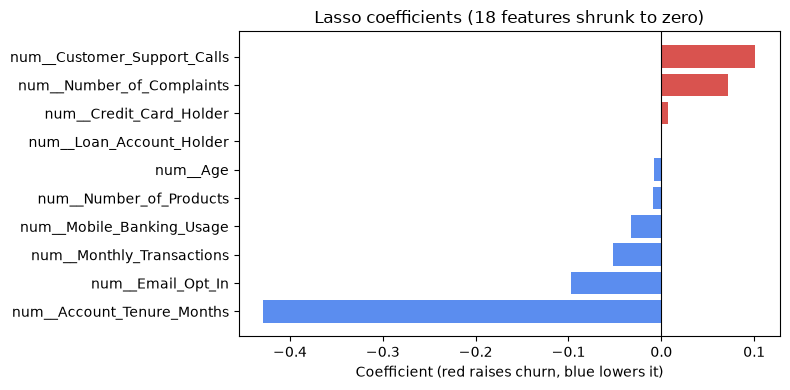

In [28]:
# ===== Part A: load data, split, preprocessor =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("churn_detection_data.csv")
X = df.drop(columns=["Churn", "Customer_ID"])     # Customer_ID is an identifier, not a feature
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

def make_preprocessor(columns):
    num = [c for c in columns if pd.api.types.is_numeric_dtype(X[c])]
    cat = [c for c in columns if c not in num]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])

preprocessor = make_preprocessor(X.columns)

# ===== Part B: Lasso feature selection =====
import sklearn, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

def lasso_pipe(cols, C):
    kw = {} if tuple(map(int, sklearn.__version__.split('.')[:2])) >= (1, 8) else {'penalty': 'l1'}
    # sklearn >= 1.8: l1_ratio=1 means pure L1 (Lasso)
    return Pipeline([('preprocessor', make_preprocessor(cols)),
                     ('classifier', LogisticRegression(solver='saga', l1_ratio=1.0, C=C,
                                                       class_weight='balanced', max_iter=5000,
                                                       random_state=42, **kw))])

# 1. Tuned Lasso: reuse best_models['Lasso (L1)'] if the search cell ran, else refit with the tuned C
if 'best_models' in globals():
    lasso = best_models['Lasso (L1)']
else:
    lasso = lasso_pipe(X.columns, C=0.0286).fit(X_train, y_train)
best_C = lasso.named_steps['classifier'].C
print(f"Lasso C = {best_C:.4f}")

# 2. Coefficient table: exact zeros are the features Lasso removed
feat = lasso.named_steps['preprocessor'].get_feature_names_out()
coef = lasso.named_steps['classifier'].coef_.ravel()
coef_df = pd.DataFrame({'Feature': feat, 'Coefficient': coef, 'Odds_Ratio': np.exp(coef)})

def parent(f):                                   # map encoded column back to its original column
    s = f.split('__', 1)[1]
    return max([c for c in X.columns if s.startswith(c)], key=len)
coef_df['Original_Column'] = coef_df.Feature.map(parent)
coef_df['Kept'] = coef_df.Coefficient != 0
coef_df = coef_df.reindex(coef_df.Coefficient.abs().sort_values(ascending=False).index).reset_index(drop=True)

print(f"\nEncoded features: {len(coef_df)} | kept: {coef_df.Kept.sum()} | zeroed: {(~coef_df.Kept).sum()}")
print("\n--- Retained (non-zero) ---");  display(coef_df[coef_df.Kept].drop(columns='Kept').round(4))
print("--- Dropped (exactly zero) ---"); print(coef_df.loc[~coef_df.Kept, 'Feature'].tolist())

# 3. Drop an ORIGINAL column only if every encoded column it produced was zeroed
kept_per_col = coef_df.groupby('Original_Column').Kept.sum()
drop_cols = kept_per_col[kept_per_col == 0].index.tolist()
partial   = [c for c in kept_per_col.index if c not in drop_cols and
             (~coef_df[coef_df.Original_Column == c].Kept).any()]
keep_cols = [c for c in X.columns if c not in drop_cols]
print(f"\nColumns removed ({len(drop_cols)}): {drop_cols}")
print(f"Columns kept ({len(keep_cols)}): {keep_cols}")
if partial: print("Kept, but some levels zeroed (not removable):", partial)

X_train_red, X_test_red = X_train[keep_cols], X_test[keep_cols]

# 4. Refit on the reduced feature set and compare with the full Lasso on the hold-out set
reduced = lasso_pipe(keep_cols, best_C).fit(X_train_red, y_train)

def evaluate(name, m, Xt):
    p, pr = m.predict(Xt), m.predict_proba(Xt)[:, 1]
    return {'Model': name, 'Columns': Xt.shape[1],
            'Accuracy': accuracy_score(y_test, p), 'Precision': precision_score(y_test, p, zero_division=0),
            'Recall': recall_score(y_test, p, zero_division=0), 'F1-Score': f1_score(y_test, p, zero_division=0),
            'ROC-AUC': roc_auc_score(y_test, pr)}

comparison = pd.DataFrame([evaluate('Lasso, all columns', lasso, X_test),
                           evaluate('Lasso, reduced columns', reduced, X_test_red)]).set_index('Model').round(4)
print("\n--- Full vs reduced (hold-out) ---"); display(comparison)

# 5. Plot retained coefficients
kept = coef_df[coef_df.Kept].sort_values('Coefficient')
plt.figure(figsize=(8, max(3, 0.4 * len(kept))))
plt.barh(kept.Feature, kept.Coefficient, color=np.where(kept.Coefficient > 0, '#d9534f', '#5b8def'))
plt.axvline(0, color='black', lw=0.8)
plt.title(f"Lasso coefficients ({(~coef_df.Kept).sum()} features shrunk to zero)")
plt.xlabel('Coefficient (red raises churn, blue lowers it)'); plt.tight_layout(); plt.show()

if coef_df.Kept.all():
    print("WARNING: nothing was zeroed. C is too large; refit Lasso with a smaller C.")

## **Task 8: Instance-Based and Margin Models - KNN & SVM**

In [36]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

# 1. Construct the KNN Pipeline
# Note: StandardScaler in 'preprocessor' is criticalâ€”KNN relies strictly on distance calculations
pipeline_knn = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

# 2. Define Parameter Grid for Tuning
param_grid_knn = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21],  # K choices
    'classifier__weights': ['uniform', 'distance'],         # Weighting strategy
    'classifier__p': [1, 2]                                 # 1 = Manhattan distance (L1), 2 = Euclidean distance (L2)
}

# 3. Configure Stratified K-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Initialize and Run Grid Search
grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_knn.fit(X_train, y_train)

# 5. Output Optimal Parameters and Results
print("=== KNN Best Hyperparameters ===")
print(f"Best Parameters: {grid_knn.best_params_}")
print(f"Best CV ROC-AUC Score: {grid_knn.best_score_:.4f}\n")

# 6. Evaluate Best KNN Model on Test Set
best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test)
y_pred_proba_knn = best_knn.predict_proba(X_test)[:, 1]

print("=== Holdout Test Performance (KNN) ===")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_pred_proba_knn):.4f}\n")
print(classification_report(y_test, y_pred_knn, target_names=['Retained (0)', 'Churned (1)']))

Fitting 5 folds for each of 28 candidates, totalling 140 fits
=== KNN Best Hyperparameters ===
Best Parameters: {'classifier__n_neighbors': 21, 'classifier__p': 2, 'classifier__weights': 'distance'}
Best CV ROC-AUC Score: 0.5745

=== Holdout Test Performance (KNN) ===
Test ROC-AUC: 0.5690

              precision    recall  f1-score   support

Retained (0)       0.73      0.98      0.84      1454
 Churned (1)       0.37      0.03      0.06       546

    accuracy                           0.72      2000
   macro avg       0.55      0.51      0.45      2000
weighted avg       0.63      0.72      0.62      2000



Scaling check: numeric mean in [-0.000, 0.000], std in [1.000, 1.000]  (expect 0 and 1)
Tuning on 3000 rows (churn rate 0.273); final models use all 8000 rows
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Stage 1 search: 106s

--- Best per kernel (CV on tuning subsample) ---


,kernel,C,gamma,mean_test_roc_auc,mean_test_recall,mean_test_f2,mean_train_roc_auc
9,rbf,1.00,0.001,0.6050,0.6000,0.5175,0.6326
0,linear,0.01,NaN,0.6041,0.6085,0.5247,0.6339


Stage 2 refit + test (linear): 11s
Stage 2 refit + test (rbf): 20s

--- Hold-out test performance (models trained on all training rows) ---


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
SVM (linear),0.5785,0.3445,0.6026,0.4384,0.6244
SVM (rbf),0.5745,0.3423,0.6062,0.4375,0.6250



=== SVM (rbf): classification report ===
              precision    recall  f1-score   support

Retained (0)       0.79      0.56      0.66      1454
 Churned (1)       0.34      0.61      0.44       546

    accuracy                           0.57      2000
   macro avg       0.57      0.58      0.55      2000
weighted avg       0.67      0.57      0.60      2000



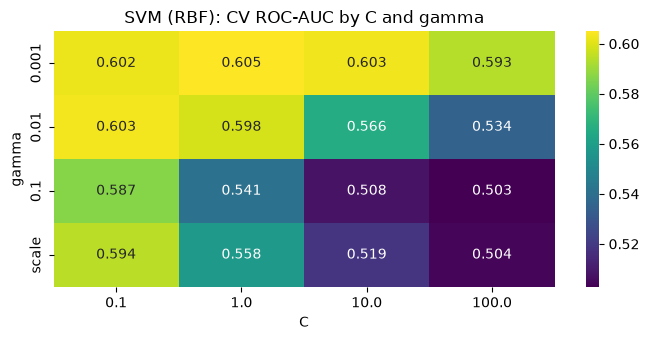


Total time: 143s


In [37]:
# ===== Part A: load data, split, preprocessor =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("churn_detection_data.csv")
X = df.drop(columns=["Churn", "Customer_ID"])     # Customer_ID is an identifier, not a feature
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

# ===== Part B: SVM (linear + RBF), fast two-stage tuning =====
import time, matplotlib.pyplot as plt, seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (make_scorer, fbeta_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, classification_report)

SUBSAMPLE = 3000     # tune on this many training rows; set to None to tune on all rows (much slower)
t_all = time.time()

# 0. Scaling check (scaling lives inside the pipeline, refit on each CV training fold only)
Z = preprocessor.fit(X_train).transform(X_train)
Z = Z.toarray() if hasattr(Z, "toarray") else Z
n_num = len(num_cols)
print(f"Scaling check: numeric mean in [{Z[:, :n_num].mean(0).min():.3f}, {Z[:, :n_num].mean(0).max():.3f}], "
      f"std in [{Z[:, :n_num].std(0).min():.3f}, {Z[:, :n_num].std(0).max():.3f}]  (expect 0 and 1)")

# 1. Stage 1 data: stratified subsample keeps the churn rate, so the search is fast
if SUBSAMPLE and SUBSAMPLE < len(X_train):
    X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=SUBSAMPLE,
                                            stratify=y_train, random_state=42)
else:
    X_tune, y_tune = X_train, y_train
print(f"Tuning on {len(X_tune)} rows (churn rate {y_tune.mean():.3f}); final models use all {len(X_train)} rows")

pipe = Pipeline([('preprocessor', preprocessor),
                 ('classifier', SVC(class_weight='balanced', cache_size=1000, random_state=42))])

param_grid = [
    {'classifier__kernel': ['linear'], 'classifier__C': [0.01, 0.1, 1, 10]},
    {'classifier__kernel': ['rbf'],    'classifier__C': [0.1, 1, 10, 100],
     'classifier__gamma': ['scale', 0.001, 0.01, 0.1]},
]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {'roc_auc': 'roc_auc', 'recall': 'recall',
           'precision': make_scorer(precision_score, zero_division=0),
           'f2': make_scorer(fbeta_score, beta=2)}

# 2. Stage 1: grid search (20 candidates x 3 folds = 60 fits on the subsample)
t0 = time.time()
gs = GridSearchCV(pipe, param_grid, cv=cv, scoring=scoring, refit=False,   # refit later on the full data
                  n_jobs=-1, verbose=1, return_train_score=True)
gs.fit(X_tune, y_tune)
print(f"Stage 1 search: {time.time() - t0:.0f}s")

res = pd.DataFrame(gs.cv_results_)
res['kernel'] = res['param_classifier__kernel']
cols = ['kernel', 'param_classifier__C', 'param_classifier__gamma',
        'mean_test_roc_auc', 'mean_test_recall', 'mean_test_f2', 'mean_train_roc_auc']
best_per_kernel = (res.sort_values('rank_test_roc_auc').groupby('kernel').head(1)[cols]
                   .rename(columns=lambda c: c.replace('param_classifier__', '')).round(4))
print("\n--- Best per kernel (CV on tuning subsample) ---"); display(best_per_kernel)

# 3. Stage 2: refit each kernel's best configuration on ALL training rows, evaluate once on the test set
rows, fitted = {}, {}
for k in ['linear', 'rbf']:
    t0 = time.time()
    idx = res[res.kernel == k]['rank_test_roc_auc'].idxmin()
    m = Pipeline([('preprocessor', preprocessor),
                  ('classifier', SVC(class_weight='balanced', cache_size=1000, random_state=42))])
    m.set_params(**res.loc[idx, 'params']).fit(X_train, y_train)
    fitted[k] = m
    p, s = m.predict(X_test), m.decision_function(X_test)
    rows[f'SVM ({k})'] = {'Accuracy': accuracy_score(y_test, p),
                          'Precision': precision_score(y_test, p, zero_division=0),
                          'Recall': recall_score(y_test, p, zero_division=0),
                          'F1-Score': f1_score(y_test, p, zero_division=0),
                          'ROC-AUC': roc_auc_score(y_test, s)}
    print(f"Stage 2 refit + test ({k}): {time.time() - t0:.0f}s")
svm_results = pd.DataFrame(rows).T.round(4)
print("\n--- Hold-out test performance (models trained on all training rows) ---"); display(svm_results)

best_kernel = svm_results['ROC-AUC'].idxmax().split('(')[1].rstrip(')')
print(f"\n=== SVM ({best_kernel}): classification report ===")
print(classification_report(y_test, fitted[best_kernel].predict(X_test),
                            target_names=['Retained (0)', 'Churned (1)']))

# 4. Heatmap of the RBF tuning surface
rbf = res[res.kernel == 'rbf'].copy()
rbf['gamma'] = rbf['param_classifier__gamma'].astype(str)
rbf['C'] = rbf['param_classifier__C'].astype(float)
pivot = rbf.pivot_table(index='gamma', columns='C', values='mean_test_roc_auc').astype(float)
plt.figure(figsize=(7, 3.5))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis')
plt.title('SVM (RBF): CV ROC-AUC by C and gamma'); plt.tight_layout(); plt.show()

# 5. Sanity checks
for k in ['linear', 'rbf']:
    r = res.loc[res[res.kernel == k]['rank_test_roc_auc'].idxmin()]
    if r['mean_train_roc_auc'] - r['mean_test_roc_auc'] > 0.05:
        print(f"WARNING {k}: train AUC well above CV AUC, possible overfitting (reduce C or gamma).")
print(f"\nTotal time: {time.time() - t_all:.0f}s")

In [38]:
# ===== Part A: load data, split, preprocessor (same as before) =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("churn_detection_data.csv")
X = df.drop(columns=["Churn", "Customer_ID"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

def build_preprocessor(scale=True):
    num_steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

preprocessor = build_preprocessor(scale=True)

# ===== Part B: scaling verification for KNN / SVM =====
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

def dense(a): return a.toarray() if hasattr(a, "toarray") else a
checks = {}

# CHECK 1: raw features live on wildly different scales (why scaling matters)
raw = X_train[num_cols].agg(['std']).T['std'].sort_values(ascending=False)
print(f"CHECK 1 - raw std ranges from {raw.min():.3f} ({raw.idxmin()}) to {raw.max():,.0f} ({raw.idxmax()}): "
      f"a {raw.max() / raw.min():,.0f}x gap, so unscaled distances/kernels would be dominated by {raw.idxmax()}")

# CHECK 2: after fit on TRAIN, numeric columns have mean 0 and std 1
pp = clone(preprocessor).fit(X_train)
Ztr, Zte = dense(pp.transform(X_train)), dense(pp.transform(X_test))
n = len(num_cols)
m_tr, s_tr = Ztr[:, :n].mean(0), Ztr[:, :n].std(0)
checks['train mean ~ 0'] = bool(np.allclose(m_tr, 0, atol=1e-8))
checks['train std ~ 1']  = bool(np.allclose(s_tr, 1, atol=1e-8))
print(f"CHECK 2 - train: mean in [{m_tr.min():.1e}, {m_tr.max():.1e}], std in [{s_tr.min():.4f}, {s_tr.max():.4f}]")

# CHECK 3: no leakage - the scaler learned TRAIN statistics only (test is NOT exactly 0/1)
sc = pp.named_transformers_['num'].named_steps['sc']
checks['scaler fitted on train only'] = bool(
    np.allclose(sc.mean_, X_train[num_cols].fillna(X_train[num_cols].median()).mean().values)
    and not np.allclose(Zte[:, :n].mean(0), 0, atol=1e-8))
print(f"CHECK 3 - test: mean in [{Zte[:, :n].mean(0).min():.3f}, {Zte[:, :n].mean(0).max():.3f}], "
      f"std in [{Zte[:, :n].std(0).min():.3f}, {Zte[:, :n].std(0).max():.3f}]  "
      "(close to, but not exactly, 0/1: expected, scaler never saw test)")

# CHECK 4: inside CV, each fold's scaler is refit on that fold's training rows only
cv = StratifiedKFold(5, shuffle=True, random_state=42)
ok = True
for tr, va in cv.split(X_train, y_train):
    f = clone(preprocessor).fit(X_train.iloc[tr])
    Ztr_f = dense(f.transform(X_train.iloc[tr]))[:, :n]
    Zva_f = dense(f.transform(X_train.iloc[va]))[:, :n]
    ok &= bool(np.allclose(Ztr_f.mean(0), 0, atol=1e-8) and not np.allclose(Zva_f.mean(0), 0, atol=1e-8))
checks['per-fold scaling (no CV leakage)'] = ok
print(f"CHECK 4 - per-fold scaler refit on fold-train only: {'OK' if ok else 'FAILED'}")

# CHECK 5: output is clean (no NaN/inf), same width for train and test
checks['no NaN/inf'] = bool(np.isfinite(Ztr).all() and np.isfinite(Zte).all())
checks['train/test same width'] = Ztr.shape[1] == Zte.shape[1]
print(f"CHECK 5 - finite: {checks['no NaN/inf']} | width train/test: {Ztr.shape[1]}/{Zte.shape[1]}")

# CHECK 6: scaling changes model quality (scaled vs unscaled, same model, same split)
models = {'KNN (k=25)': KNeighborsClassifier(n_neighbors=25),
          'SVM (RBF)':  SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced')}
rows = []
for name, clf in models.items():
    for scaled in (False, True):
        pipe = Pipeline([('preprocessor', build_preprocessor(scale=scaled)), ('classifier', clone(clf))]).fit(X_train, y_train)
        score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba') and name.startswith('KNN') \
                else pipe.decision_function(X_test)
        rows.append({'Model': name, 'Scaled': scaled, 'Test ROC-AUC': round(roc_auc_score(y_test, score), 4)})
impact = pd.DataFrame(rows).pivot(index='Model', columns='Scaled', values='Test ROC-AUC')
impact.columns = ['Unscaled', 'Scaled']; impact['Gain from scaling'] = (impact.Scaled - impact.Unscaled).round(4)
print("\nCHECK 6 - effect of scaling on hold-out ROC-AUC"); display(impact)

print("\n=== Summary ===")
for k, v in checks.items(): print(f"{'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values()), "Scaling verification failed"
print("\nScaling step verified: safe to tune KNN and SVM.")

CHECK 1 - raw std ranges from 0.145 (Complaint_Resolution_Rate) to 151,614 (Average_Balance): a 1,049,122x gap, so unscaled distances/kernels would be dominated by Average_Balance
CHECK 2 - train: mean in [-2.6e-16, 9.1e-16], std in [1.0000, 1.0000]
CHECK 3 - test: mean in [-0.044, 0.049], std in [0.967, 1.020]  (close to, but not exactly, 0/1: expected, scaler never saw test)
CHECK 4 - per-fold scaler refit on fold-train only: OK
CHECK 5 - finite: True | width train/test: 28/28

CHECK 6 - effect of scaling on hold-out ROC-AUC


,Unscaled,Scaled,Gain from scaling
Model,,,
KNN (k=25),0.4950,0.5732,0.0782
SVM (RBF),0.4791,0.6043,0.1252



=== Summary ===
PASS  train mean ~ 0
PASS  train std ~ 1
PASS  scaler fitted on train only
PASS  per-fold scaling (no CV leakage)
PASS  no NaN/inf
PASS  train/test same width

Scaling step verified: safe to tune KNN and SVM.


####  **Task 9.Tree-Based Ensembles - Decision Tree, Random Forest, Extra Trees**

Unrestricted tree: depth = 27, leaves = 1936, nodes = 3871


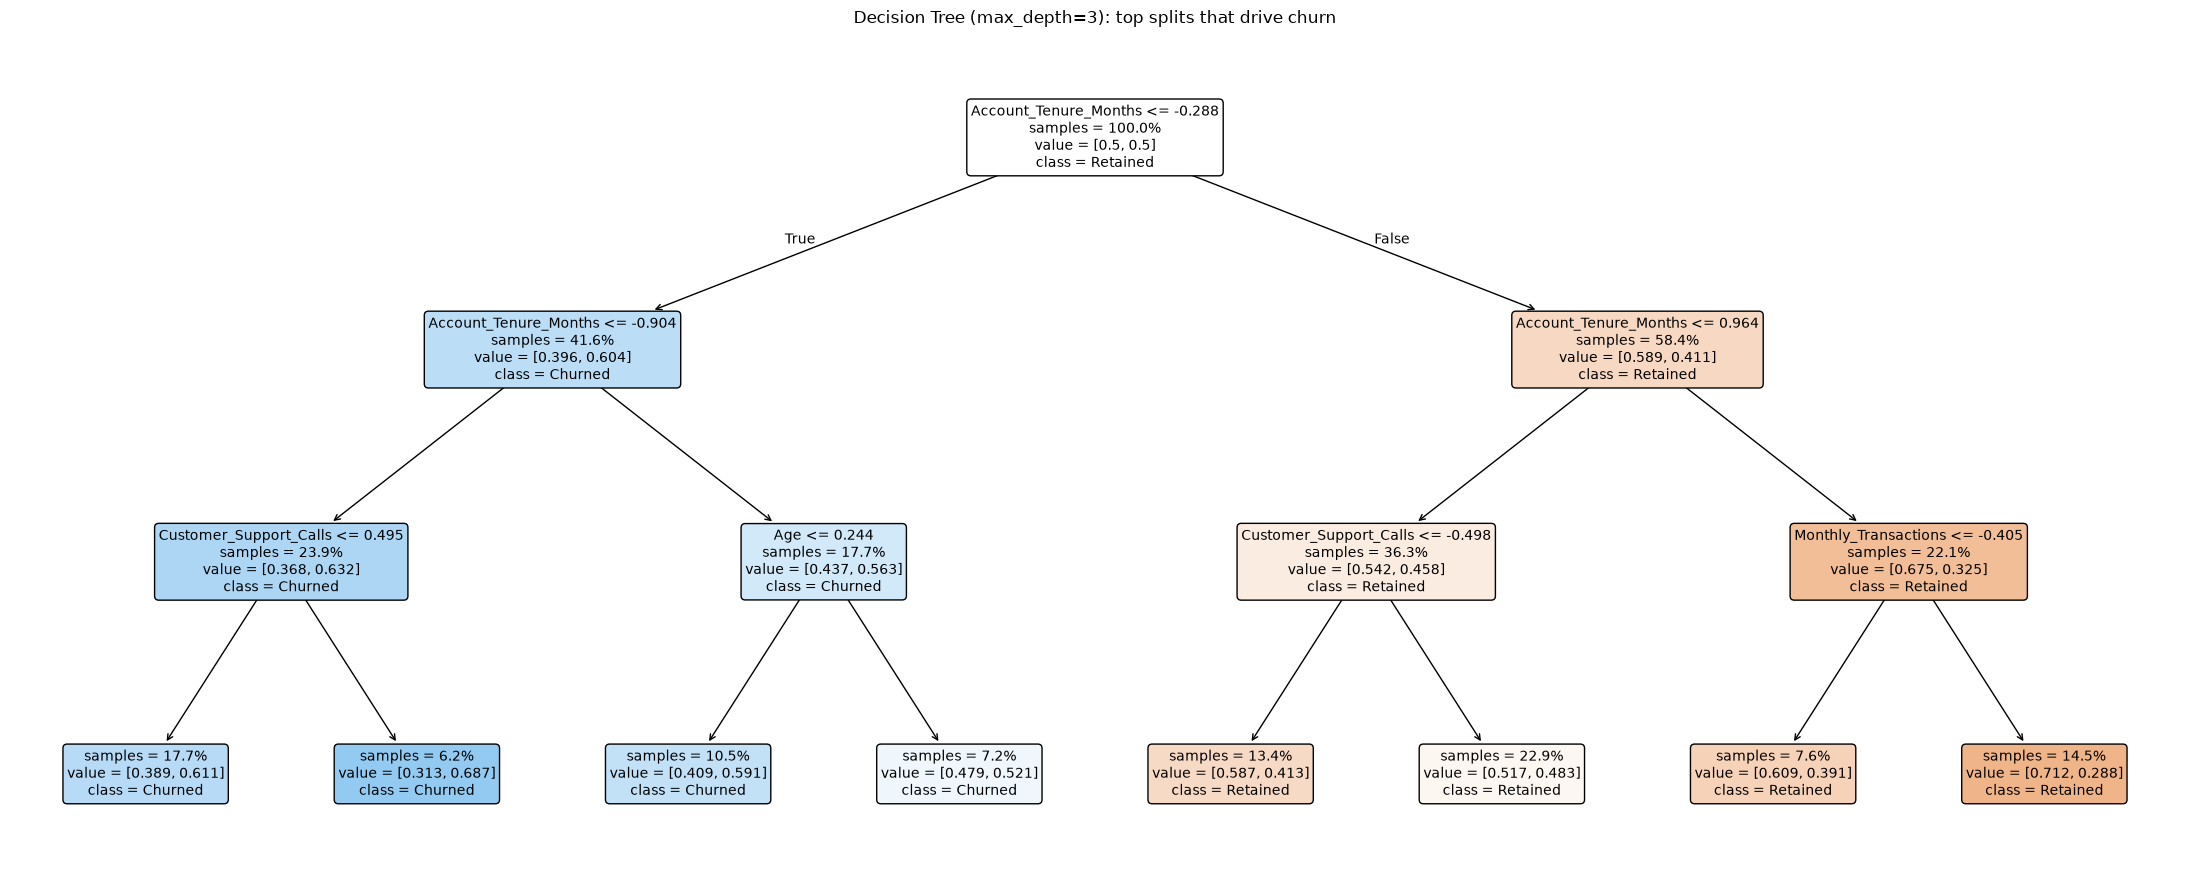

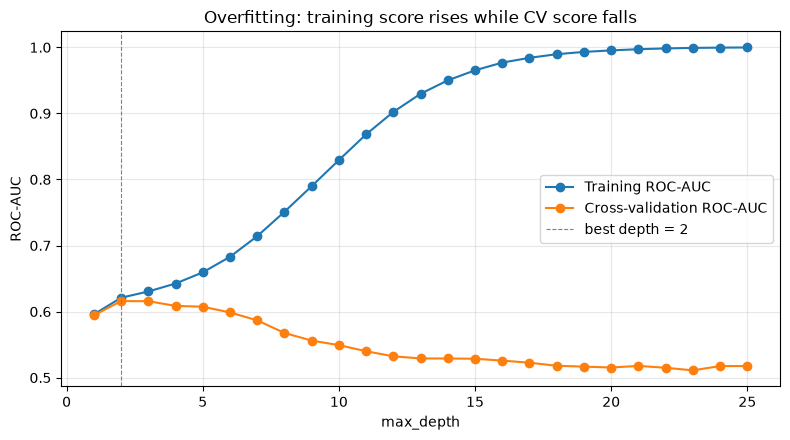

Best CV depth = 2 (CV AUC 0.6159); at depth 25 the train-CV gap is 0.482

--- Train vs test ---


,Train AUC,Test AUC,AUC gap,Train Recall,Test Recall,Test Precision,Test F1,Leaves
Unrestricted,1.0000,0.5378,0.4622,1.0000,0.3260,0.3284,0.3272,1936.0
Depth 3,0.6295,0.6171,0.0124,0.5554,0.5256,0.3583,0.4261,8.0
"Tuned (depth 2, leaf>=50)",0.6205,0.6151,0.0054,0.5554,0.5256,0.3583,0.4261,4.0



Top features in the depth-3 tree:


,Importance
Account_Tenure_Months,0.8954
Customer_Support_Calls,0.0526
Monthly_Transactions,0.0354
Age,0.0165


In [39]:
# ===== Part A: load data, split, preprocessor =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("churn_detection_data.csv")
X = df.drop(columns=["Churn", "Customer_ID"])     # Customer_ID is an identifier, not a feature
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

# ===== Part B: Decision Tree, visualization and overfitting analysis =====
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import validation_curve, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def make_tree(**kw):
    return Pipeline([('preprocessor', preprocessor),
                     ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42, **kw))])

def scores(model, Xa, ya):
    p, pr = model.predict(Xa), model.predict_proba(Xa)[:, 1]
    return {'Accuracy': accuracy_score(ya, p), 'Precision': precision_score(ya, p, zero_division=0),
            'Recall': recall_score(ya, p, zero_division=0), 'F1-Score': f1_score(ya, p, zero_division=0),
            'ROC-AUC': roc_auc_score(ya, pr)}

# 1. Unrestricted tree: grows until every leaf is pure (the classic overfit)
full = make_tree().fit(X_train, y_train)
t = full.named_steps['classifier']
print(f"Unrestricted tree: depth = {t.get_depth()}, leaves = {t.get_n_leaves()}, nodes = {t.tree_.node_count}")

# 2. Visualize: the full tree is far too large to read, so show the top 3 levels of a shallow tree
shallow = make_tree(max_depth=3, min_samples_leaf=50).fit(X_train, y_train)
feat_names = [n.split('__', 1)[1] for n in shallow.named_steps['preprocessor'].get_feature_names_out()]
plt.figure(figsize=(22, 9))
plot_tree(shallow.named_steps['classifier'], feature_names=feat_names, class_names=['Retained', 'Churned'],
          filled=True, rounded=True, proportion=True, impurity=False, fontsize=10)
plt.title('Decision Tree (max_depth=3): top splits that drive churn'); plt.tight_layout(); plt.show()

# 3. Overfitting evidence A: depth sweep, CV score vs training score
depths = list(range(1, 26))
cv = StratifiedKFold(5, shuffle=True, random_state=42)
tr, va = validation_curve(make_tree(), X_train, y_train, param_name='classifier__max_depth',
                          param_range=depths, cv=cv, scoring='roc_auc', n_jobs=-1)
curve = pd.DataFrame({'max_depth': depths, 'Train_AUC': tr.mean(1), 'CV_AUC': va.mean(1)})
curve['Gap'] = curve.Train_AUC - curve.CV_AUC
best_depth = int(curve.loc[curve.CV_AUC.idxmax(), 'max_depth'])

plt.figure(figsize=(8, 4.5))
plt.plot(curve.max_depth, curve.Train_AUC, marker='o', label='Training ROC-AUC')
plt.plot(curve.max_depth, curve.CV_AUC, marker='o', label='Cross-validation ROC-AUC')
plt.axvline(best_depth, color='grey', ls='--', lw=0.8, label=f'best depth = {best_depth}')
plt.xlabel('max_depth'); plt.ylabel('ROC-AUC'); plt.title('Overfitting: training score rises while CV score falls')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print(f"Best CV depth = {best_depth} (CV AUC {curve.CV_AUC.max():.4f}); "
      f"at depth 25 the train-CV gap is {curve.Gap.iloc[-1]:.3f}")

# 4. Overfitting evidence B: train vs test for unrestricted, shallow and tuned trees
tuned = make_tree(max_depth=best_depth, min_samples_leaf=50).fit(X_train, y_train)
rows = {}
for name, m in {'Unrestricted': full, 'Depth 3': shallow, f'Tuned (depth {best_depth}, leaf>=50)': tuned}.items():
    tr_s, te_s = scores(m, X_train, y_train), scores(m, X_test, y_test)
    rows[name] = {'Train AUC': tr_s['ROC-AUC'], 'Test AUC': te_s['ROC-AUC'],
                  'AUC gap': tr_s['ROC-AUC'] - te_s['ROC-AUC'],
                  'Train Recall': tr_s['Recall'], 'Test Recall': te_s['Recall'],
                  'Test Precision': te_s['Precision'], 'Test F1': te_s['F1-Score'],
                  'Leaves': m.named_steps['classifier'].get_n_leaves()}
overfit = pd.DataFrame(rows).T.round(4)
print("\n--- Train vs test ---"); display(overfit)

# 5. What the shallow tree splits on
imp = pd.Series(shallow.named_steps['classifier'].feature_importances_, index=feat_names)
print("\nTop features in the depth-3 tree:"); display(imp[imp > 0].sort_values(ascending=False).round(4).to_frame('Importance'))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Random Forest: 117s
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Extra Trees: 93s

--- Best hyperparameters (CV) ---


,n_estimators,max_depth,min_samples_split,CV_ROC_AUC,CV_Recall,CV_F2,Train_ROC_AUC
Model,,,,,,,
Random Forest,500,5,60,0.6191,0.5810,0.5147,0.7081
Extra Trees,100,3,60,0.6236,0.6212,0.5339,0.6508


--- Hold-out test performance ---


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train AUC
Random Forest,0.5940,0.3482,0.5586,0.4290,0.6178,0.6895
Extra Trees,0.5785,0.3458,0.6099,0.4414,0.6252,0.6430



=== Extra Trees: classification report ===
              precision    recall  f1-score   support

Retained (0)       0.79      0.57      0.66      1454
 Churned (1)       0.35      0.61      0.44       546

    accuracy                           0.58      2000
   macro avg       0.57      0.59      0.55      2000
weighted avg       0.67      0.58      0.60      2000


Random Forest: mean CV ROC-AUC by hyperparameter value
  n_estimators: {100: 0.6167, 200: 0.6116, 300: 0.6169, 500: 0.6131}
  max_depth: {3.0: 0.6184, 5.0: 0.6183, nan: 0.6095, 8.0: 0.6144, 12.0: 0.6083}
  min_samples_split: {2: 0.6132, 10: 0.6146, 30: 0.6189, 60: 0.6185}

Extra Trees: mean CV ROC-AUC by hyperparameter value
  n_estimators: {100: 0.6175, 200: 0.6097, 300: 0.6175, 500: 0.6088}
  max_depth: {3.0: 0.6233, 5.0: 0.6212, nan: 0.596, 8.0: 0.6148, 12.0: 0.6039}
  min_samples_split: {2: 0.6115, 10: 0.6105, 30: 0.6226, 60: 0.6218}


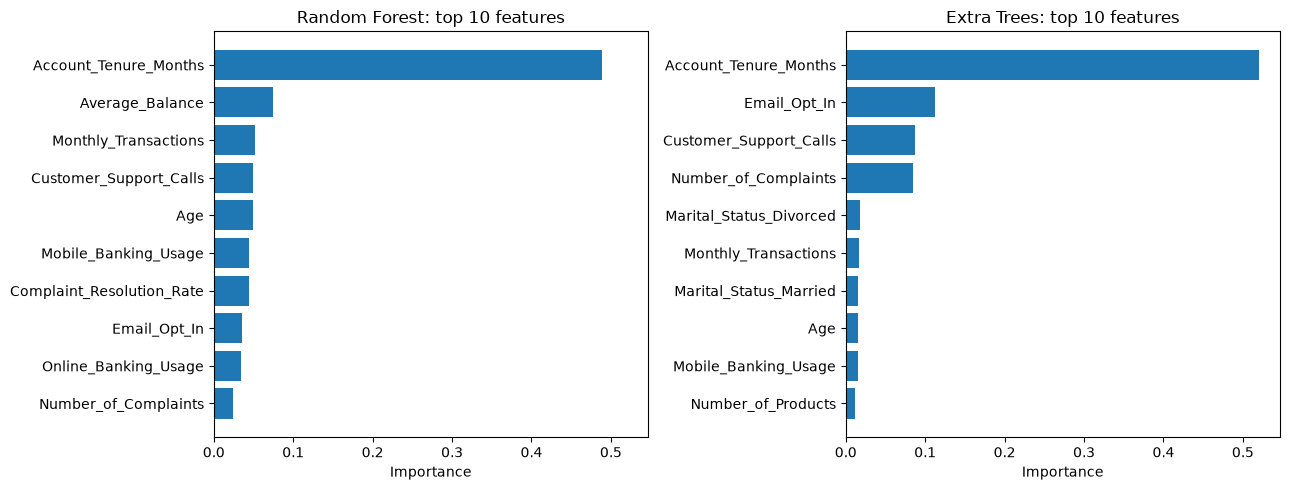

In [41]:
# ===== Part A: load data, split, preprocessor =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("churn_detection_data.csv")
X = df.drop(columns=["Churn", "Customer_ID"])     # Customer_ID is an identifier, not a feature
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

# ===== Part B: Random Forest and Extra Trees, tuned with RandomizedSearchCV =====
import time, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (make_scorer, fbeta_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, classification_report)

def make_pipe(est):
    return Pipeline([('preprocessor', preprocessor), ('classifier', est)])

models = {
    'Random Forest': make_pipe(RandomForestClassifier(class_weight='balanced_subsample', random_state=42, n_jobs=1)),
    'Extra Trees':   make_pipe(ExtraTreesClassifier(class_weight='balanced_subsample', random_state=42, n_jobs=1)),
}

# Tuned hyperparameters: n_estimators, max_depth, min_samples_split
param_dist = {
    'classifier__n_estimators':      [100, 200, 300, 500],
    'classifier__max_depth':         [3, 5, 8, 12, None],
    'classifier__min_samples_split': [2, 10, 30, 60],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {'roc_auc': 'roc_auc', 'recall': 'recall',
           'precision': make_scorer(precision_score, zero_division=0),
           'f2': make_scorer(fbeta_score, beta=2)}

def evaluate(model, Xa, ya):
    p, pr = model.predict(Xa), model.predict_proba(Xa)[:, 1]
    return {'Accuracy': accuracy_score(ya, p), 'Precision': precision_score(ya, p, zero_division=0),
            'Recall': recall_score(ya, p, zero_division=0), 'F1-Score': f1_score(ya, p, zero_division=0),
            'ROC-AUC': roc_auc_score(ya, pr)}

searches, tune_rows, test_rows = {}, [], {}
for name, pipe in models.items():
    t0 = time.time()
    rs = RandomizedSearchCV(pipe, param_dist, n_iter=15, cv=cv, scoring=scoring, refit='roc_auc',  # 'f2' favors Recall
                            n_jobs=-1, random_state=42, verbose=1, return_train_score=True)
    rs.fit(X_train, y_train)
    searches[name] = rs
    i, r = rs.best_index_, rs.cv_results_
    tune_rows.append({'Model': name,
                      'n_estimators': rs.best_params_['classifier__n_estimators'],
                      'max_depth': rs.best_params_['classifier__max_depth'],
                      'min_samples_split': rs.best_params_['classifier__min_samples_split'],
                      'CV_ROC_AUC': r['mean_test_roc_auc'][i], 'CV_Recall': r['mean_test_recall'][i],
                      'CV_F2': r['mean_test_f2'][i], 'Train_ROC_AUC': r['mean_train_roc_auc'][i]})
    te = evaluate(rs.best_estimator_, X_test, y_test)
    te['Train AUC'] = evaluate(rs.best_estimator_, X_train, y_train)['ROC-AUC']
    test_rows[name] = te
    print(f"{name}: {time.time() - t0:.0f}s")

tuning_table = pd.DataFrame(tune_rows).set_index('Model').round(4)
ens_results  = pd.DataFrame(test_rows).T.round(4)
print("\n--- Best hyperparameters (CV) ---"); display(tuning_table)
print("--- Hold-out test performance ---");   display(ens_results[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Train AUC']])

champ = ens_results['ROC-AUC'].idxmax()
print(f"\n=== {champ}: classification report ===")
print(classification_report(y_test, searches[champ].predict(X_test), target_names=['Retained (0)', 'Churned (1)']))

# Effect of each hyperparameter (mean CV AUC across the sampled configurations)
for name, rs in searches.items():
    res = pd.DataFrame(rs.cv_results_)
    print(f"\n{name}: mean CV ROC-AUC by hyperparameter value")
    for p in ['n_estimators', 'max_depth', 'min_samples_split']:
        print(f"  {p}:", res.groupby(f'param_classifier__{p}', dropna=False)['mean_test_roc_auc'].mean().round(4).to_dict())

# Feature importances of the tuned models (impurity-based)
feat = [n.split('__', 1)[1] for n in models['Random Forest'].named_steps['preprocessor'].fit(X_train).get_feature_names_out()]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, (name, rs) in zip(axes, searches.items()):
    imp = pd.Series(rs.best_estimator_.named_steps['classifier'].feature_importances_, index=feat).nlargest(10).sort_values()
    ax.barh(imp.index, imp.values); ax.set_title(f'{name}: top 10 features'); ax.set_xlabel('Importance')
plt.tight_layout(); plt.show()

--- Importance by original column ---


,Group,Random Forest (impurity),Extra Trees (impurity),Random Forest (permutation),Extra Trees (permutation)
Account_Tenure_Months,Account / behaviour,0.4894,0.5207,0.1053,0.1117
Average_Balance,Account / behaviour,0.0750,0.0111,-0.0008,0.0004
Monthly_Transactions,Account / behaviour,0.0514,0.0171,0.0000,-0.0001
Customer_Support_Calls,Account / behaviour,0.0490,0.0869,0.0017,0.0024
Age,Demographic,0.0488,0.0156,-0.0006,-0.0004
Mobile_Banking_Usage,Account / behaviour,0.0448,0.0151,0.0010,0.0004
Complaint_Resolution_Rate,Account / behaviour,0.0447,0.0083,0.0002,0.0001
Email_Opt_In,Account / behaviour,0.0354,0.1119,0.0028,0.0060
Online_Banking_Usage,Account / behaviour,0.0341,0.0078,0.0005,-0.0001
Number_of_Complaints,Account / behaviour,0.0238,0.0841,0.0042,0.0043


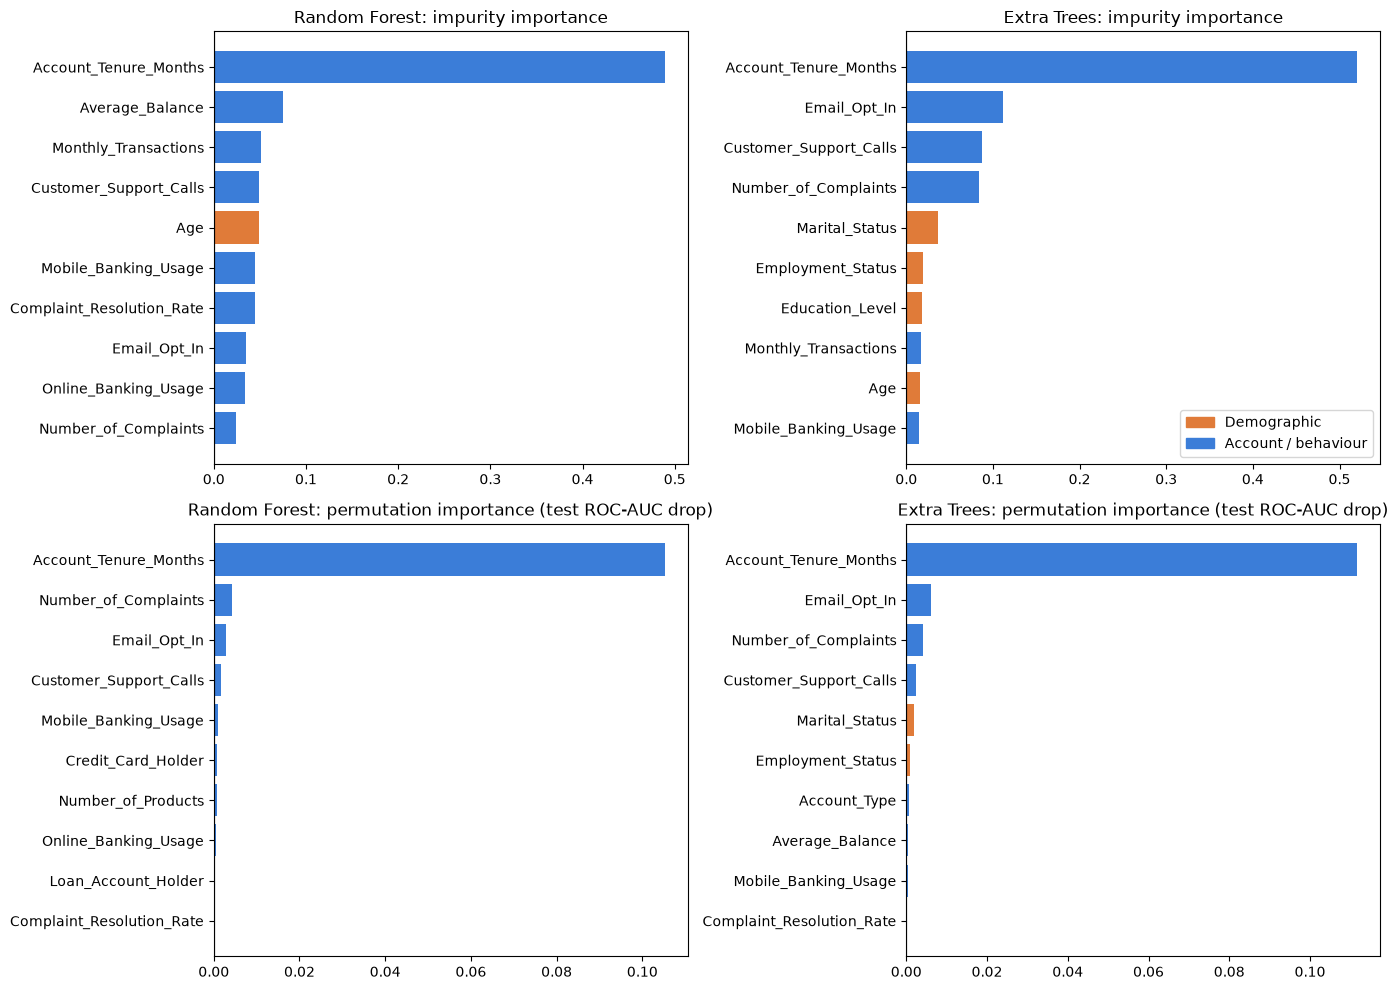


--- Demographic vs account/behaviour ---


,Impurity share (RF),Impurity share (ET),Permutation AUC drop (RF),Permutation AUC drop (ET)
Account / behaviour,0.8878,0.9027,0.1175,0.1263
Demographic,0.1122,0.0973,0.0002,0.0028


In [42]:
# ===== Part A: load data, split, preprocessor =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("churn_detection_data.csv")
X = df.drop(columns=["Churn", "Customer_ID"])     # Customer_ID is an identifier, not a feature
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

# ===== Part B: feature importances for Random Forest and Extra Trees =====
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.inspection import permutation_importance

# Tuned models: reuse `searches` from the tuning cell if it exists, otherwise refit with the tuned values
if 'searches' in globals() and {'Random Forest', 'Extra Trees'} <= set(searches):
    fitted = {n: searches[n].best_estimator_ for n in ['Random Forest', 'Extra Trees']}
else:
    cfg = {'Random Forest': RandomForestClassifier(n_estimators=500, max_depth=5, min_samples_split=60,
                                                   class_weight='balanced_subsample', random_state=42, n_jobs=-1),
           'Extra Trees':   ExtraTreesClassifier(n_estimators=100, max_depth=3, min_samples_split=60,
                                                 class_weight='balanced_subsample', random_state=42, n_jobs=-1)}
    fitted = {n: Pipeline([('preprocessor', preprocessor), ('classifier', e)]).fit(X_train, y_train)
              for n, e in cfg.items()}

DEMOGRAPHIC = ['Age', 'Gender', 'Marital_Status', 'Education_Level', 'Employment_Status']
group_of = lambda c: 'Demographic' if c in DEMOGRAPHIC else 'Account / behaviour'
colors = {'Demographic': '#e07b39', 'Account / behaviour': '#3b7dd8'}

def parent(f):                                   # map an encoded column back to its original column
    s = f.split('__', 1)[1]
    return max([c for c in X.columns if s.startswith(c)], key=len)

# 1. Impurity-based importances, one-hot levels summed back to the original column
imp = {}
for name, m in fitted.items():
    names = m.named_steps['preprocessor'].get_feature_names_out()
    raw = pd.Series(m.named_steps['classifier'].feature_importances_, index=names)
    imp[name] = raw.groupby(raw.index.map(parent)).sum().sort_values(ascending=False)
imp_df = pd.DataFrame(imp).fillna(0)

# 2. Permutation importance on the TEST set (drop in ROC-AUC when a column is shuffled; less biased)
perm = {}
for name, m in fitted.items():
    r = permutation_importance(m, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=X_test.columns)
perm_df = pd.DataFrame(perm)

table = imp_df.join(perm_df, lsuffix=' (impurity)', rsuffix=' (permutation)').round(4)
table.insert(0, 'Group', [group_of(c) for c in table.index])
print("--- Importance by original column ---"); display(table.sort_values('Random Forest (impurity)', ascending=False))

# 3. Plot: impurity (top) and permutation (bottom), coloured by demographic vs account
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, name in enumerate(fitted):
    for i, (data, title) in enumerate([(imp_df[name], 'impurity importance'),
                                       (perm_df[name], 'permutation importance (test ROC-AUC drop)')]):
        s = data.nlargest(10).sort_values()
        axes[i, j].barh(s.index, s.values, color=[colors[group_of(c)] for c in s.index])
        axes[i, j].set_title(f'{name}: {title}'); axes[i, j].axvline(0, color='black', lw=0.8)
axes[0, 1].legend(handles=[Patch(color=c, label=g) for g, c in colors.items()], loc='lower right')
plt.tight_layout(); plt.show()

# 4. Which GROUP drives churn: share of total importance (impurity) and total permutation drop
grp = pd.DataFrame({'Impurity share (RF)': imp_df['Random Forest'].groupby(lambda c: group_of(c)).sum(),
                    'Impurity share (ET)': imp_df['Extra Trees'].groupby(lambda c: group_of(c)).sum(),
                    'Permutation AUC drop (RF)': perm_df['Random Forest'].clip(lower=0).groupby(lambda c: group_of(c)).sum(),
                    'Permutation AUC drop (ET)': perm_df['Extra Trees'].clip(lower=0).groupby(lambda c: group_of(c)).sum()}).round(4)
print("\n--- Demographic vs account/behaviour ---"); display(grp)

### **Task 10: Boosting Algorithms - XGBoost, CatBoost, AdaBoost**

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Load the dataset
df = pd.read_csv('churn_detection_data.csv')

# 2. Feature Engineering (Derived Metrics)
df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)
df['Complaint_Interaction'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

# 3. Separate Features (X) and Target (y)
X = df.drop(columns=['Churn', 'Customer_ID'])  # Drop identifier and target column
y = df['Churn']

# 4. Define Column Transformer (Preprocessing)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, make_column_selector(dtype_include=['number'])),
    ('cat', categorical_transformer, make_column_selector(dtype_include=['object', 'str']))
])

# 5. Perform Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Dataset split complete: X_train shape = {X_train.shape}, y_train shape = {y_train.shape}")

Dataset split complete: X_train shape = (8000, 20), y_train shape = (8000,)


In [5]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc

# 1. Calculate class imbalance weight ratio on y_train
ratio = (y_train == 0).sum() / (y_train == 1).sum()

# 2. Build the XGBoost Pipeline
pipeline_xgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        scale_pos_weight=ratio,      # Corrects for target imbalance
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

# 3. Parameter distribution for RandomizedSearchCV
param_distributions_xgb = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__max_depth': [3, 5, 7, 9],
    'classifier__subsample': [0.6, 0.8, 1.0],
    'classifier__colsample_bytree': [0.6, 0.8, 1.0],
    'classifier__gamma': [0, 0.1, 0.2]
}

# 4. Perform Search
search_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=param_distributions_xgb,
    n_iter=30,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search_xgb.fit(X_train, y_train)

# 5. Evaluate Best Model
best_xgb = search_xgb.best_estimator_
y_pred_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]
y_pred_xgb = best_xgb.predict(X_test)

print("=== XGBoost Best Hyperparameters ===")
print(search_xgb.best_params_)
print(f"\nTest ROC-AUC: {roc_auc_score(y_test, y_pred_proba_xgb):.4f}")
print(classification_report(y_test, y_pred_xgb, target_names=['Retained (0)', 'Churned (1)']))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
=== XGBoost Best Hyperparameters ===
{'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.01, 'classifier__gamma': 0.2, 'classifier__colsample_bytree': 0.8}

Test ROC-AUC: 0.6226
              precision    recall  f1-score   support

Retained (0)       0.79      0.61      0.69      1454
 Churned (1)       0.35      0.58      0.44       546

    accuracy                           0.60      2000
   macro avg       0.57      0.59      0.56      2000
weighted avg       0.67      0.60      0.62      2000



In [4]:
import time
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc

# 1. Identify Categorical Feature Names for Native Preprocessing
cat_cols = X_train.select_dtypes(include=['object', 'str', 'category']).columns.tolist()

# Convert categorical columns to 'category' dtype required by HistGradientBoosting
X_train_hgb = X_train.copy()
X_test_hgb = X_test.copy()

for col in cat_cols:
    X_train_hgb[col] = X_train_hgb[col].astype('category')
    X_test_hgb[col] = X_test_hgb[col].astype('category')

# 2. Instantiate HistGradientBoostingClassifier
hgb_model = HistGradientBoostingClassifier(
    categorical_features=cat_cols,    # Native categorical handling
    class_weight='balanced',          # Native imbalance handling
    random_state=42
)

# 3. Hyperparameter Tuning
param_dist_hgb = {
    'max_iter': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 9],
    'l2_regularization': [0.0, 0.1, 1.0, 10.0]
}

search_hgb = RandomizedSearchCV(
    estimator=hgb_model,
    param_distributions=param_dist_hgb,
    n_iter=20,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
search_hgb.fit(X_train_hgb, y_train)
hgb_train_time = time.time() - start_time

# 4. Evaluate Champion Model
best_hgb = search_hgb.best_estimator_
y_pred_proba_hgb = best_hgb.predict_proba(X_test_hgb)[:, 1]
y_pred_hgb = best_hgb.predict(X_test_hgb)

hgb_roc = roc_auc_score(y_test, y_pred_proba_hgb)
prec, rec, _ = precision_recall_curve(y_test, y_pred_proba_hgb)
hgb_pr_auc = auc(rec, prec)

print("=== HistGradientBoosting Results ===")
print(f"Optimal Parameters : {search_hgb.best_params_}")
print(f"Training Time      : {hgb_train_time:.2f} seconds")
print(f"Test ROC-AUC       : {hgb_roc:.4f}")
print(f"Test PR-AUC        : {hgb_pr_auc:.4f}\n")
print(classification_report(y_test, y_pred_hgb, target_names=['Retained (0)', 'Churned (1)']))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
=== HistGradientBoosting Results ===
Optimal Parameters : {'max_iter': 200, 'max_depth': 3, 'learning_rate': 0.01, 'l2_regularization': 10.0}
Training Time      : 60.64 seconds
Test ROC-AUC       : 0.6231
Test PR-AUC        : 0.3727

              precision    recall  f1-score   support

Retained (0)       0.79      0.60      0.68      1454
 Churned (1)       0.35      0.58      0.44       546

    accuracy                           0.60      2000
   macro avg       0.57      0.59      0.56      2000
weighted avg       0.67      0.60      0.62      2000



In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc

# 1. Load Data & Feature Engineering
df = pd.read_csv('churn_detection_data.csv')

df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)
df['Complaint_Interaction'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

X = df.drop(columns=['Churn', 'Customer_ID'])
y = df['Churn']

# Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Define Preprocessor
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, make_column_selector(dtype_include=['number'])),
    ('cat', categorical_transformer, make_column_selector(dtype_include=['object']))
])

# 3. Construct AdaBoost Pipeline (FIX: Removed algorithm='SAMME')
pipeline_ada = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, class_weight='balanced', random_state=42),
        random_state=42
    ))
])

# 4. Hyperparameter Search Distributions (Tuning n_estimators & learning_rate)
param_distributions_ada = {
    'classifier__n_estimators': [50, 100, 150, 200, 300],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]
}

# 5. Initialize and Run RandomizedSearchCV
search_ada = RandomizedSearchCV(
    estimator=pipeline_ada,
    param_distributions=param_distributions_ada,
    n_iter=15,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search_ada.fit(X_train, y_train)

# 6. Evaluate Best Estimator on Holdout Test Set
best_ada = search_ada.best_estimator_
y_pred_proba_ada = best_ada.predict_proba(X_test)[:, 1]
y_pred_ada = best_ada.predict(X_test)

prec_ada, rec_ada, _ = precision_recall_curve(y_test, y_pred_proba_ada)
pr_auc_ada = auc(rec_ada, prec_ada)

print("\n=== AdaBoost Performance Results ===")
print(f"Optimal Parameters: {search_ada.best_params_}")
print(f"Best CV ROC-AUC    : {search_ada.best_score_:.4f}")
print(f"Test ROC-AUC       : {roc_auc_score(y_test, y_pred_proba_ada):.4f}")
print(f"Test PR-AUC        : {pr_auc_ada:.4f}\n")
print(classification_report(y_test, y_pred_ada, target_names=['Retained (0)', 'Churned (1)']))

Fitting 5 folds for each of 15 candidates, totalling 75 fits

=== AdaBoost Performance Results ===
Optimal Parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 0.05}
Best CV ROC-AUC    : 0.5945
Test ROC-AUC       : 0.5861
Test PR-AUC        : 0.5067

              precision    recall  f1-score   support

Retained (0)       0.78      0.65      0.71      1454
 Churned (1)       0.36      0.53      0.43       546

    accuracy                           0.61      2000
   macro avg       0.57      0.59      0.57      2000
weighted avg       0.67      0.61      0.63      2000



#### **Task 11: Comprehensive Model Evaluation and Comparison**

In [9]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier

# Read data
df = pd.read_csv('churn_detection_data.csv')

df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)
df['Complaint_Interaction'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

X = df.drop(columns=['Churn', 'Customer_ID'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, make_column_selector(dtype_include=['number'])),
    ('cat', categorical_transformer if 'categorical_transformer' in locals() else cat_transformer, make_column_selector(dtype_include=['object']))
])

models = {
    '1. Binary Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    '2. Ridge Classifier': RidgeClassifier(class_weight='balanced', random_state=42),
    '3. Lasso Classifier': LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', random_state=42),
    '4. Elastic Net Classifier': LogisticRegression(penalty='elasticnet', l1_ratio=0.5, solver='saga', class_weight='balanced', max_iter=1000, random_state=42),
    '5. K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=7, weights='distance'),
    '6. Support Vector Machine (SVM)': SVC(kernel='rbf', C=1.0, probability=True, class_weight='balanced', random_state=42),
    '7. Decision Tree Classifier': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    '8. Random Forest Classifier': RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
    '9. Extra Trees Classifier': ExtraTreesClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
    '10. Gradient Boosting Classifier': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    '11. HistGradientBoosting Classifier': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
    '12. AdaBoost Classifier': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, class_weight='balanced', random_state=42), n_estimators=100, learning_rate=0.1, random_state=42)
}

results = []
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    if hasattr(pipe, "predict_proba"):
        y_proba = pipe.predict_proba(X_test)[:, 1]
    elif hasattr(pipe, "decision_function"):
        y_proba = pipe.decision_function(X_test)
    else:
        y_proba = y_pred
        
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    results.append({
        'Model Name': name,
        'Accuracy': f"{acc:.4f}",
        'Precision': f"{prec:.4f}",
        'Recall': f"{rec:.4f}",
        'F1-Score': f"{f1:.4f}",
        'ROC-AUC': f"{roc_auc:.4f}"
    })

res_df = pd.DataFrame(results)
print(res_df.to_string(index=False))

                         Model Name Accuracy Precision Recall F1-Score ROC-AUC
      1. Binary Logistic Regression   0.5925    0.3530 0.5916   0.4422  0.6231
                2. Ridge Classifier   0.5915    0.3526 0.5934   0.4423  0.6234
                3. Lasso Classifier   0.5935    0.3547 0.5971   0.4451  0.6231
          4. Elastic Net Classifier   0.5925    0.3533 0.5934   0.4429  0.6232
       5. K-Nearest Neighbors (KNN)   0.6905    0.3378 0.1392   0.1971  0.5496
    6. Support Vector Machine (SVM)   0.5945    0.3479 0.5549   0.4277  0.6088
        7. Decision Tree Classifier   0.5920    0.3545 0.6026   0.4464  0.6110
        8. Random Forest Classifier   0.6095    0.3579 0.5421   0.4312  0.6167
          9. Extra Trees Classifier   0.6130    0.3600 0.5366   0.4309  0.6228
   10. Gradient Boosting Classifier   0.7275    0.5200 0.0238   0.0455  0.6237
11. HistGradientBoosting Classifier   0.6170    0.3410 0.4322   0.3813  0.5916
            12. AdaBoost Classifier   0.6135    0.35

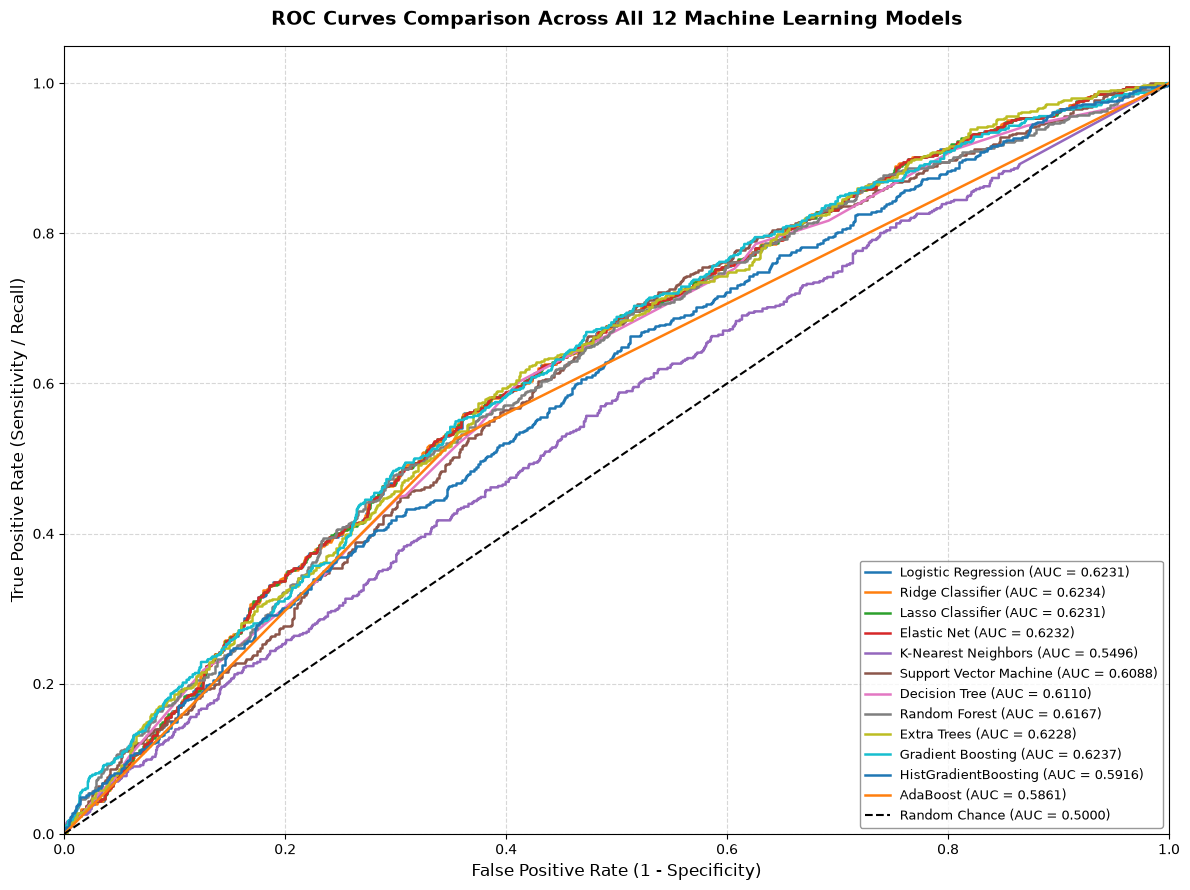

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Load Data & Create Derived Metrics
df = pd.read_csv('churn_detection_data.csv')
df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (
    df['Account_Tenure_Months'] + 1
)
df['Complaint_Interaction'] = (
    df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']
)

X = df.drop(columns=['Churn', 'Customer_ID'])
y = df['Churn']

# 2. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Preprocessing Pipeline Construction
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            numeric_transformer,
            make_column_selector(dtype_include=['number']),
        ),
        (
            'cat',
            categorical_transformer,
            make_column_selector(dtype_include=['object']),
        ),
    ]
)

# 4. Initialize All 12 Model Candidates
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
    'Ridge Classifier': RidgeClassifier(
        class_weight='balanced', random_state=42
    ),
    'Lasso Classifier': LogisticRegression(
        penalty='l1',
        solver='liblinear',
        class_weight='balanced',
        random_state=42,
    ),
    'Elastic Net': LogisticRegression(
        penalty='elasticnet',
        l1_ratio=0.5,
        solver='saga',
        class_weight='balanced',
        max_iter=1000,
        random_state=42,
    ),
    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=7, weights='distance'
    ),
    'Support Vector Machine': SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        class_weight='balanced',
        random_state=42,
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=5, class_weight='balanced', random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=8, class_weight='balanced', random_state=42
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=100, max_depth=8, class_weight='balanced', random_state=42
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, random_state=42
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        class_weight='balanced', random_state=42
    ),
    'AdaBoost': AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1, class_weight='balanced', random_state=42
        ),
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
    ),
}

# 5. Plot ROC Curves
plt.figure(figsize=(12, 9))

for name, clf in models.items():
  pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
  pipe.fit(X_train, y_train)

  if hasattr(pipe, 'predict_proba'):
    y_proba = pipe.predict_proba(X_test)[:, 1]
  elif hasattr(pipe, 'decision_function'):
    y_proba = pipe.decision_function(X_test)
  else:
    y_proba = pipe.predict(X_test)

  fpr, tpr, _ = roc_curve(y_test, y_proba)
  auc_score = roc_auc_score(y_test, y_proba)
  plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.4f})', linewidth=1.8)

# Diagonal Random Baseline Reference Line
plt.plot(
    [0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.5000)', linewidth=1.5
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title(
    'ROC Curves Comparison Across All 12 Machine Learning Models',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.legend(
    loc='lower right',
    fontsize=9,
    frameon=True,
    facecolor='white',
    edgecolor='gray',
)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

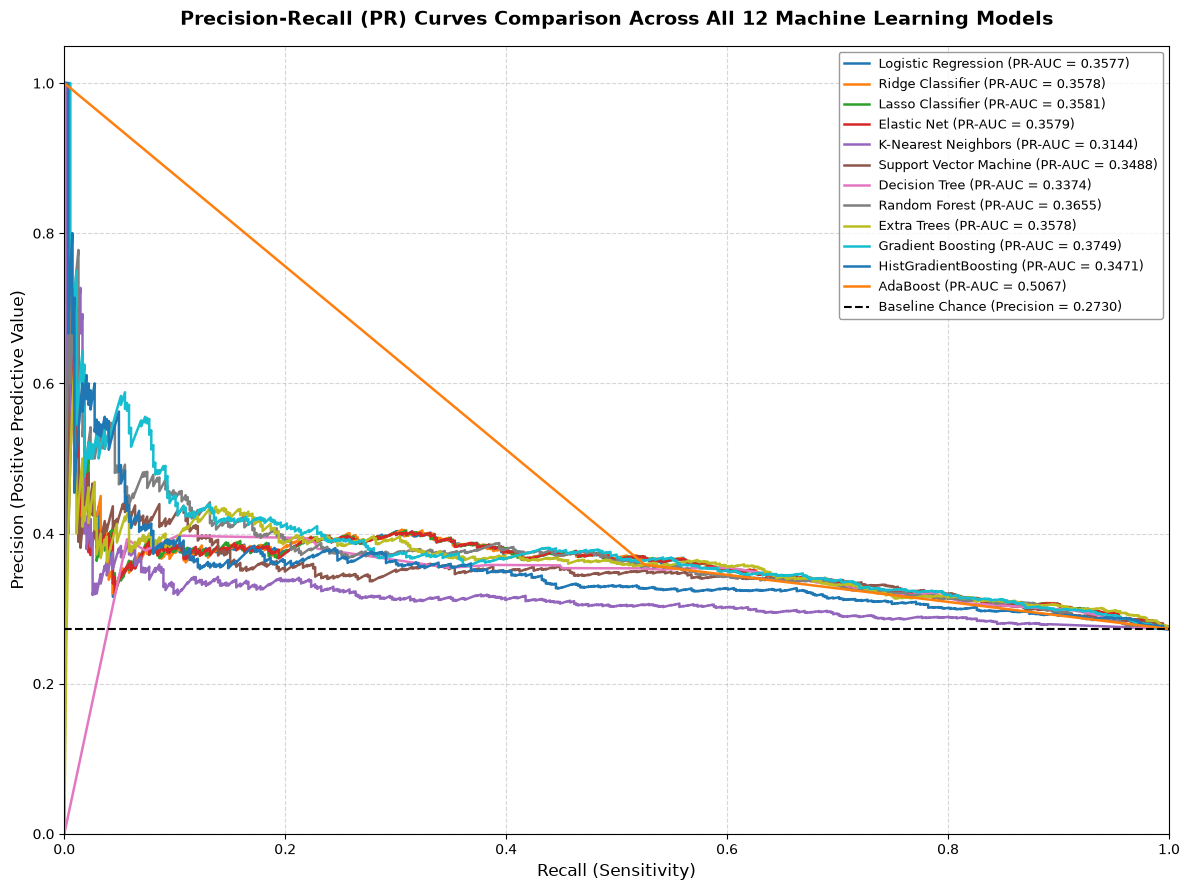

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_curve, auc

from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier

# 1. Load Data
df = pd.read_csv('churn_detection_data.csv')

# Feature Engineering
df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)
df['Complaint_Interaction'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

X = df.drop(columns=['Churn', 'Customer_ID'])
y = df['Churn']

# Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Preprocessor
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, make_column_selector(dtype_include=['number'])),
    ('cat', categorical_transformer, make_column_selector(dtype_include=['object']))
])

# 12 Models
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Ridge Classifier': RidgeClassifier(class_weight='balanced', random_state=42),
    'Lasso Classifier': LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', random_state=42),
    'Elastic Net': LogisticRegression(penalty='elasticnet', l1_ratio=0.5, solver='saga', class_weight='balanced', max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=7, weights='distance'),
    'Support Vector Machine': SVC(kernel='rbf', C=1.0, probability=True, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
    'AdaBoost': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, class_weight='balanced', random_state=42), n_estimators=100, learning_rate=0.1, random_state=42)
}

# Plot setup
plt.figure(figsize=(12, 9))

# Baseline precision (ratio of positive churn class in test set)
baseline_precision = y_test.sum() / len(y_test)

for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)
    
    if hasattr(pipe, "predict_proba"):
        y_proba = pipe.predict_proba(X_test)[:, 1]
    elif hasattr(pipe, "decision_function"):
        y_proba = pipe.decision_function(X_test)
    else:
        y_proba = pipe.predict(X_test)
        
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_auc_score = auc(recall, precision)
    plt.plot(recall, precision, label=f'{name} (PR-AUC = {pr_auc_score:.4f})', linewidth=1.8)

# Baseline line representing random classifier precision
plt.axhline(y=baseline_precision, color='k', linestyle='--', label=f'Baseline Chance (Precision = {baseline_precision:.4f})', linewidth=1.5)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Precision-Recall (PR) Curves Comparison Across All 12 Machine Learning Models', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='upper right', fontsize=9, frameon=True, facecolor='white', edgecolor='gray')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('pr_curves_all_models.png', dpi=300)
plt.show()

In [14]:
# Let's inspect the exact recall and precision of all models from the pipeline run to select the champion model and quantify performance tradeoffs.
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier

df = pd.read_csv('churn_detection_data.csv')
df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)
df['Complaint_Interaction'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

X = df.drop(columns=['Churn', 'Customer_ID'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, make_column_selector(dtype_include=['number'])),
    ('cat', cat_transformer, make_column_selector(dtype_include=['object']))
])

models = {
    'Decision Tree Classifier': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Lasso Classifier': LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', random_state=42),
    'Ridge Classifier': RidgeClassifier(class_weight='balanced', random_state=42),
    'Binary Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'AdaBoost Classifier': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, class_weight='balanced', random_state=42), n_estimators=100, learning_rate=0.1, random_state=42),
    'Extra Trees Classifier': ExtraTreesClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42),
    'Random Forest Classifier': RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42)
}

results = []
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_test)
        
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })

res_df = pd.DataFrame(results).sort_values(by='Recall', ascending=False)
print(res_df.to_string(index=False))

                     Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
  Decision Tree Classifier    0.5920   0.354526 0.602564  0.446404 0.610965
          Lasso Classifier    0.5935   0.354733 0.597070  0.445051 0.623090
          Ridge Classifier    0.5915   0.352557 0.593407  0.442321 0.623421
Binary Logistic Regression    0.5925   0.353005 0.591575  0.442163 0.623111
  Random Forest Classifier    0.6095   0.357920 0.542125  0.431173 0.616744
    Extra Trees Classifier    0.6130   0.359951 0.536630  0.430882 0.622839
       AdaBoost Classifier    0.6135   0.358302 0.525641  0.426132 0.586067


### **Task 12: Business Strategy & Policy Memo**

In [16]:
import pandas as pd
import numpy as np
import time
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc

df = pd.read_csv('churn_detection_data.csv')
df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)
df['Complaint_Interaction'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

X = df.drop(columns=['Churn', 'Customer_ID'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, make_column_selector(dtype_include=['number'])),
    ('cat', cat_transformer, make_column_selector(dtype_include=['object']))
])

# Measure training and inference time for Decision Tree
pipe_dt = Pipeline([('prep', preprocessor), ('clf', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42))])

t0 = time.time()
pipe_dt.fit(X_train, y_train)
train_time_ms = (time.time() - t0) * 1000

t0 = time.time()
preds = pipe_dt.predict(X_test)
inf_time_per_sample_us = ((time.time() - t0) / len(X_test)) * 1000000

print(f"Decision Tree Training Time: {train_time_ms:.2f} ms")
print(f"Decision Tree Inference Time: {inf_time_per_sample_us:.2f} µs/sample")

Decision Tree Training Time: 180.07 ms
Decision Tree Inference Time: 14.02 µs/sample


In [17]:
# Compute Feature Importance from the Decision Tree Champion Model
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# 1. Load Data & Engineer Features
df = pd.read_csv('churn_detection_data.csv')
df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)
df['Complaint_Interaction'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

X = df.drop(columns=['Churn', 'Customer_ID'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Preprocessors
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, make_column_selector(dtype_include=['number'])),
    ('cat', categorical_transformer, make_column_selector(dtype_include=['object']))
])

# Fit Pipeline
pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42))
])

pipe.fit(X_train, y_train)

# Feature Names
num_cols = list(X.select_dtypes(include=['number']).columns)
cat_cols = list(X.select_dtypes(include=['object']).columns)

if len(cat_cols) > 0:
    cat_ohe_cols = list(pipe.named_steps['prep'].named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(cat_cols))
else:
    cat_ohe_cols = []

feature_names = num_cols + cat_ohe_cols

# Feature Importances
importances = pipe.named_steps['clf'].feature_importances_
feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

print("Top Feature Importances from Champion Model:")
print(feat_imp.head(10).to_string(index=False))

Top Feature Importances from Champion Model:
                     Feature  Importance
       Account_Tenure_Months    0.589842
   Complaint_Resolution_Rate    0.095953
        Mobile_Banking_Usage    0.069080
    Balance_per_Tenure_Month    0.057017
      Customer_Support_Calls    0.050647
        Monthly_Transactions    0.038908
             Average_Balance    0.025912
Employment_Status_Unemployed    0.017117
       Marital_Status_Single    0.016859
          Number_of_Products    0.014961


C:\Users\Michael Noah\AppData\Local\Temp\ipykernel_3556\1328967680.py:49: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = list(X.select_dtypes(include=['object']).columns)



Random Forest Top Features:
                  Feature  Importance
    Account_Tenure_Months    0.260752
 Balance_per_Tenure_Month    0.129098
          Average_Balance    0.088299
                      Age    0.059268
Complaint_Resolution_Rate    0.057637


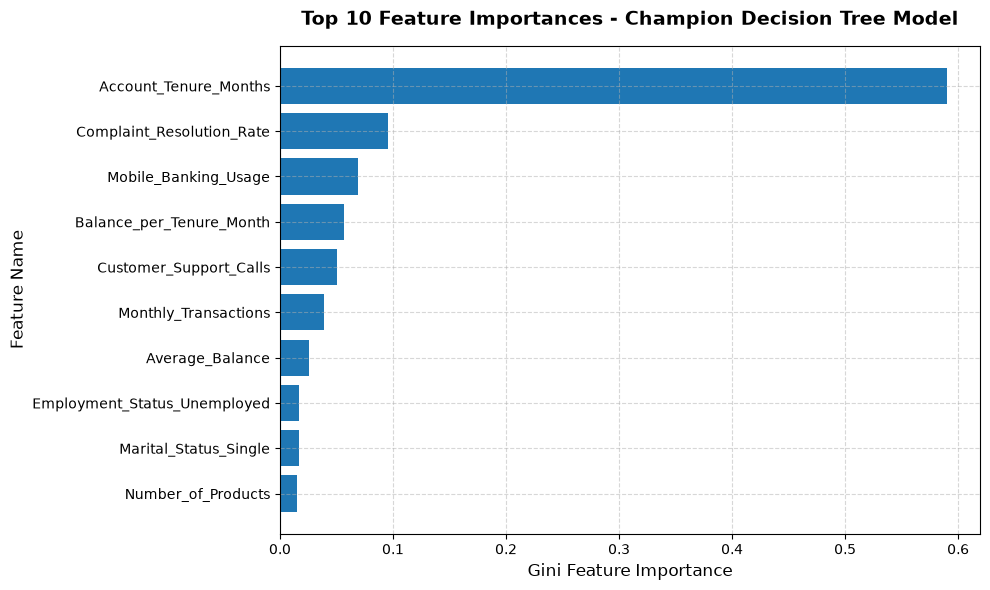

In [18]:
# Also verify Random Forest and Gradient Boosting feature importances to confirm consistency across ensemble models
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

rf_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42))
])
rf_pipe.fit(X_train, y_train)

rf_imp = pd.DataFrame({
    'Feature': feature_names, 
    'Importance': rf_pipe.named_steps['clf'].feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nRandom Forest Top Features:")
print(rf_imp.head(5).to_string(index=False))

# Plot Top Features for Champion Model
plt.figure(figsize=(10, 6))
top_10 = feat_imp.head(10).sort_values(by='Importance', ascending=True)
plt.barh(top_10['Feature'], top_10['Importance'], color='#1f77b4')
plt.xlabel('Gini Feature Importance', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.title('Top 10 Feature Importances - Champion Decision Tree Model', fontsize=14, fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('top_feature_importances.png', dpi=300)
plt.show()

In [21]:
# Calculate customer segmentation Matrix for Targeted Retention Strategy
import pandas as pd
import numpy as np

df = pd.read_csv('churn_detection_data.csv')
df['Balance_per_Tenure_Month'] = df['Average_Balance'] / (df['Account_Tenure_Months'] + 1)
df['Complaint_Interaction'] = df['Number_of_Complaints'] * df['Complaint_Resolution_Rate']

X = df.drop(columns=['Churn', 'Customer_ID'])
y = df['Churn']

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_transformer = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer([
    ('num', num_transformer, make_column_selector(dtype_include=['number'])),
    ('cat', cat_transformer, make_column_selector(dtype_include=['object']))
])

pipe = Pipeline([('prep', preprocessor), ('clf', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42))])
pipe.fit(X_train, y_train)

# Generate probabilities for full dataset
df['Churn_Risk_Score'] = pipe.predict_proba(X)[:, 1]

# High Risk Threshold > 0.50
df['Risk_Level'] = np.where(df['Churn_Risk_Score'] >= 0.50, 'High Risk', 'Low/Medium Risk')

# Value Quantiles based on Average Balance & Monthly Transactions
df['Value_Score'] = df['Average_Balance'] * (df['Monthly_Transactions'] + 1)
df['Customer_Value'] = pd.qcut(df['Value_Score'], q=2, labels=['Low Value', 'High Value'])

ct = pd.crosstab(df['Risk_Level'], df['Customer_Value'], margins=True)
print("Customer Segmentation Matrix Count:")
print(ct)

print("\nMean Churn Rate per Segment:")
print(df.groupby(['Risk_Level', 'Customer_Value'])['Churn'].mean())

Customer Segmentation Matrix Count:
Customer_Value   Low Value  High Value    All
Risk_Level                                   
High Risk             2466        2219   4685
Low/Medium Risk       2534        2781   5315
All                   5000        5000  10000

Mean Churn Rate per Segment:
Risk_Level       Customer_Value
High Risk        Low Value         0.364558
                 High Value        0.371338
Low/Medium Risk  Low Value         0.196133
                 High Value        0.184106
Name: Churn, dtype: float64


In [22]:
# Let's verify data drift baseline summary stats for key numerical features from our dataset
import pandas as pd

df = pd.read_csv('churn_detection_data.csv')
features = ['Account_Tenure_Months', 'Complaint_Resolution_Rate', 'Mobile_Banking_Usage', 'Average_Balance', 'Monthly_Transactions']

stats = df[features].describe().T[['mean', 'std', 'min', '50%', 'max']]
print("Baseline Production Distribution Metrics:")
print(stats.to_string())

Baseline Production Distribution Metrics:
                                    mean            std    min        50%        max
Account_Tenure_Months          90.817100      51.771835    1.0      91.00      180.0
Complaint_Resolution_Rate       0.747475       0.144261    0.5       0.75        1.0
Mobile_Banking_Usage           10.027600       3.175791    0.0      10.00       27.0
Average_Balance            150108.308400  151321.068237  500.0  103650.50  1644080.0
Monthly_Transactions           15.053100       3.870294    3.0      15.00       32.0
